# Is South Carolina Heating Up?
### Three angles on 60 years of NOAA weather data (1966–2025)

This notebook walks through the whole project step by step. It calls the same
functions as `run_all.py` (the code lives in `src/`), so the numbers and figures
here are exactly the ones in the report and the slides.

| Step | What happens |
|---|---|
| Task 1 | Download daily data for 10 South Carolina stations from NOAA |
| Task 2 | Clean it, check it, and analyse it from **three angles** |
| Task 3 | Visualise every result with **Matplotlib** |

**Run it:** open this notebook from the project folder and choose *Run All*
(needs `pip install -r requirements.txt` plus Jupyter).

In [1]:
import sys
sys.path.insert(0, "src")

import pandas as pd
from IPython.display import Image, Markdown, display

import config, download_data, clean_data, quality_check
import angle1_where, angle2_when, angle3_extremes

pd.set_option("display.precision", 2)

## Task 1 – Download the data

Source: NOAA NCEI **GHCN-Daily**, the database behind NOAA's *Past Weather* pages.
Every station has one CSV file at a public URL:

In [2]:
print(config.NOAA_URL)
pd.DataFrame([(sid, city, region) for sid, (city, region) in config.STATIONS.items()],
             columns=["NOAA station ID", "City", "Region"])

https://www.ncei.noaa.gov/data/global-historical-climatology-network-daily/access/{station}.csv


,NOAA station ID,City,Region
0,USW00013880,Charleston (Airport),Coast
1,USW00013782,Charleston (Downtown),Coast
2,USW00093831,Beaufort,Coast
3,USW00013883,Columbia,Midlands
4,USW00013744,Florence,Midlands
5,USC00388440,Sumter,Midlands
6,USW00003870,Greenville-Spartanburg,Upstate
7,USW00093846,Anderson,Upstate
8,USC00381770,Clemson,Upstate
9,USC00389350,Rock Hill,Upstate


The 10 stations were picked because they have at least 330 days of data in
(almost) every year from 1966 to 2025 and cover the Coast, Midlands and Upstate.
The trimmed downloads are already in `data/raw/`, so the next cell is switched off.
Set `DOWNLOAD = True` to fetch fresh data from NOAA (about 1 minute).

In [3]:
DOWNLOAD = False
if DOWNLOAD:
    download_data.main()

raw = pd.read_csv(config.RAW_DIR / "USW00013880.csv")
print(f"Charleston Airport raw file: {len(raw):,} rows")
raw[["DATE", "TMAX", "TMIN", "PRCP", "TMAX_ATTRIBUTES"]].tail()

Charleston Airport raw file: 24,107 rows


,DATE,TMAX,TMIN,PRCP,TMAX_ATTRIBUTES
24102,2025-12-27,261,106.0,0,",,1"
24103,2025-12-28,206,133.0,0,",,1"
24104,2025-12-29,222,72.0,0,",,1"
24105,2025-12-30,100,6.0,0,",,1"
24106,2025-12-31,117,-22.0,0,",,1"


Temperatures are in **tenths of °C** and rain in **tenths of mm** – the cleaning step converts them.

## Task 2a – Clean the data

* convert to °F and inches
* drop values that failed NOAA's quality checks
* drop impossible days (high lower than low)
* only use years with at least 330 valid days

In [4]:
daily, annual = clean_data.main()
annual.head()

Cleaned 217,782 station-days from 10 stations (1966-2025).
                  city  days_in_file  pct_missing_temp  pct_missing_rain  usable_temp_years  usable_rain_years
  Charleston (Airport)         21915              0.00              0.00                 60                 60
 Charleston (Downtown)         21894              0.20              0.20                 60                 60
              Beaufort         20703              1.05              1.66                 55                 55
              Columbia         21915              0.00              0.00                 60                 60
              Florence         21914              0.14              0.01                 60                 60
                Sumter         21852              2.58              0.83                 57                 59
Greenville-Spartanburg         21915              0.00              0.00                 60                 60
              Anderson         21872              0.0

,station,city,region,year,temp_days,rain_days,tavg_f,tmax_f,tmin_f,hot_days,...,freeze_days,last_spring_freeze_doy,first_fall_freeze_doy,freeze_free_days,rain_total_in,wet_days,heavy_rain_days,max_1day_rain_in,pct_rain_from_1in_days,longest_dry_spell
0,USC00381770,Clemson,Upstate,1966,364,365,59.94,71.73,48.19,8.0,...,72.0,101.0,307.0,205.0,47.39,111.0,3.0,3.92,46.94,16.0
1,USC00381770,Clemson,Upstate,1967,364,365,60.31,72.48,48.16,0.0,...,64.0,82.0,302.0,219.0,53.36,108.0,4.0,3.34,42.72,18.0
2,USC00381770,Clemson,Upstate,1968,365,366,59.87,72.26,47.50,14.0,...,92.0,86.0,304.0,217.0,56.95,115.0,5.0,3.47,52.30,26.0
3,USC00381770,Clemson,Upstate,1969,365,365,60.27,71.98,48.56,15.0,...,79.0,88.0,310.0,221.0,52.04,104.0,4.0,3.56,51.04,12.0
4,USC00381770,Clemson,Upstate,1970,365,365,61.65,73.69,49.60,12.0,...,73.0,93.0,320.0,226.0,39.42,121.0,1.0,3.56,34.06,21.0


## Task 2b – Check the data: the neighbour test

Each station is compared with the average of the other nine. A healthy station
stays close to zero; a station that drifts more than 3 °F is flagged.

In [5]:
check = quality_check.main()

  saved figures/fig01_station_map.png
    station                   city   region  max_5yr_drift_f  suspect
USW00013880   Charleston (Airport)    Coast             1.26    False
USW00013782  Charleston (Downtown)    Coast             1.24    False
USW00093831               Beaufort    Coast             1.57    False
USW00013883               Columbia Midlands             2.10    False
USW00013744               Florence Midlands             1.50    False
USC00388440                 Sumter Midlands             5.02     True
USW00003870 Greenville-Spartanburg  Upstate             1.33    False
USW00093846               Anderson  Upstate             1.59    False
USC00381770                Clemson  Upstate             1.74    False
USC00389350              Rock Hill  Upstate             1.63    False


  saved figures/fig02_data_quality_check.png


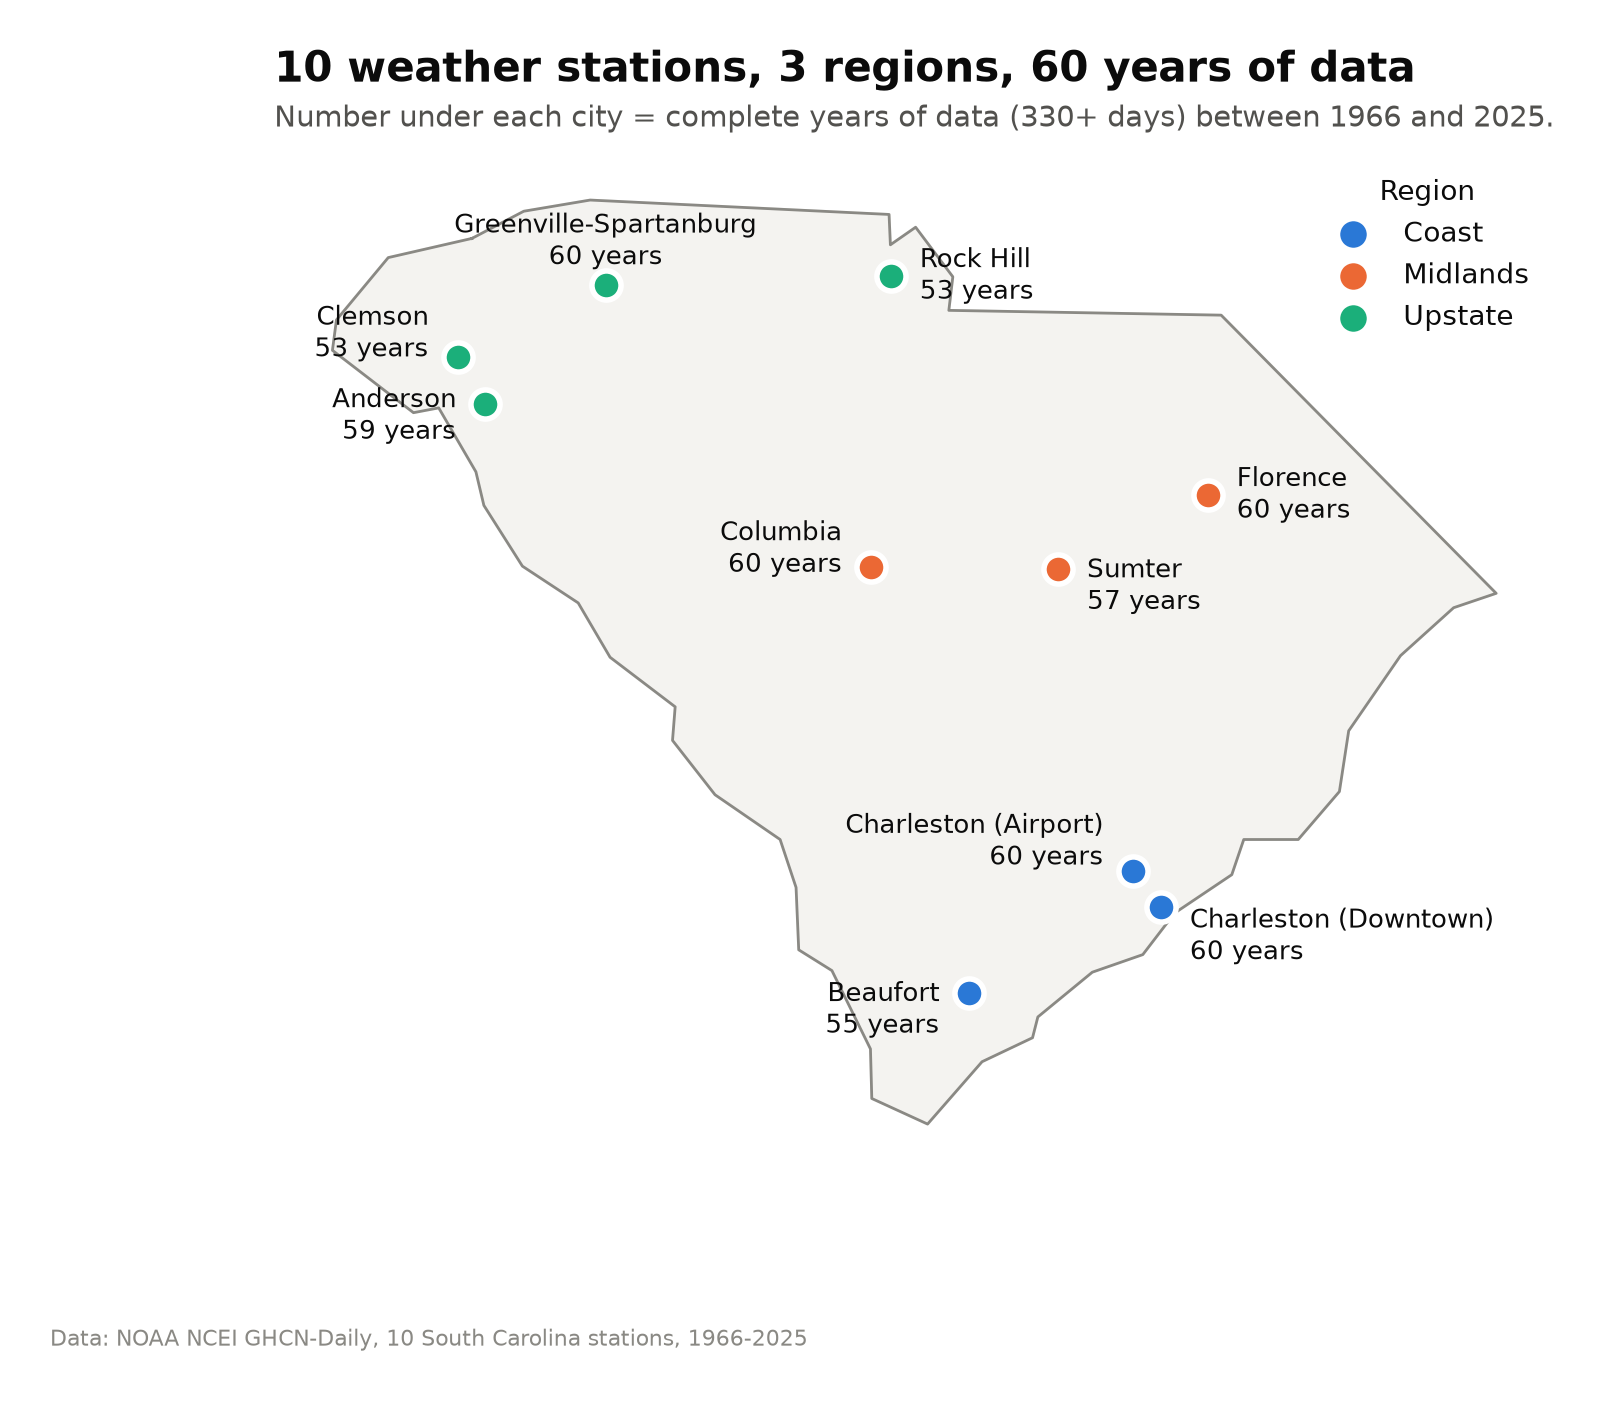

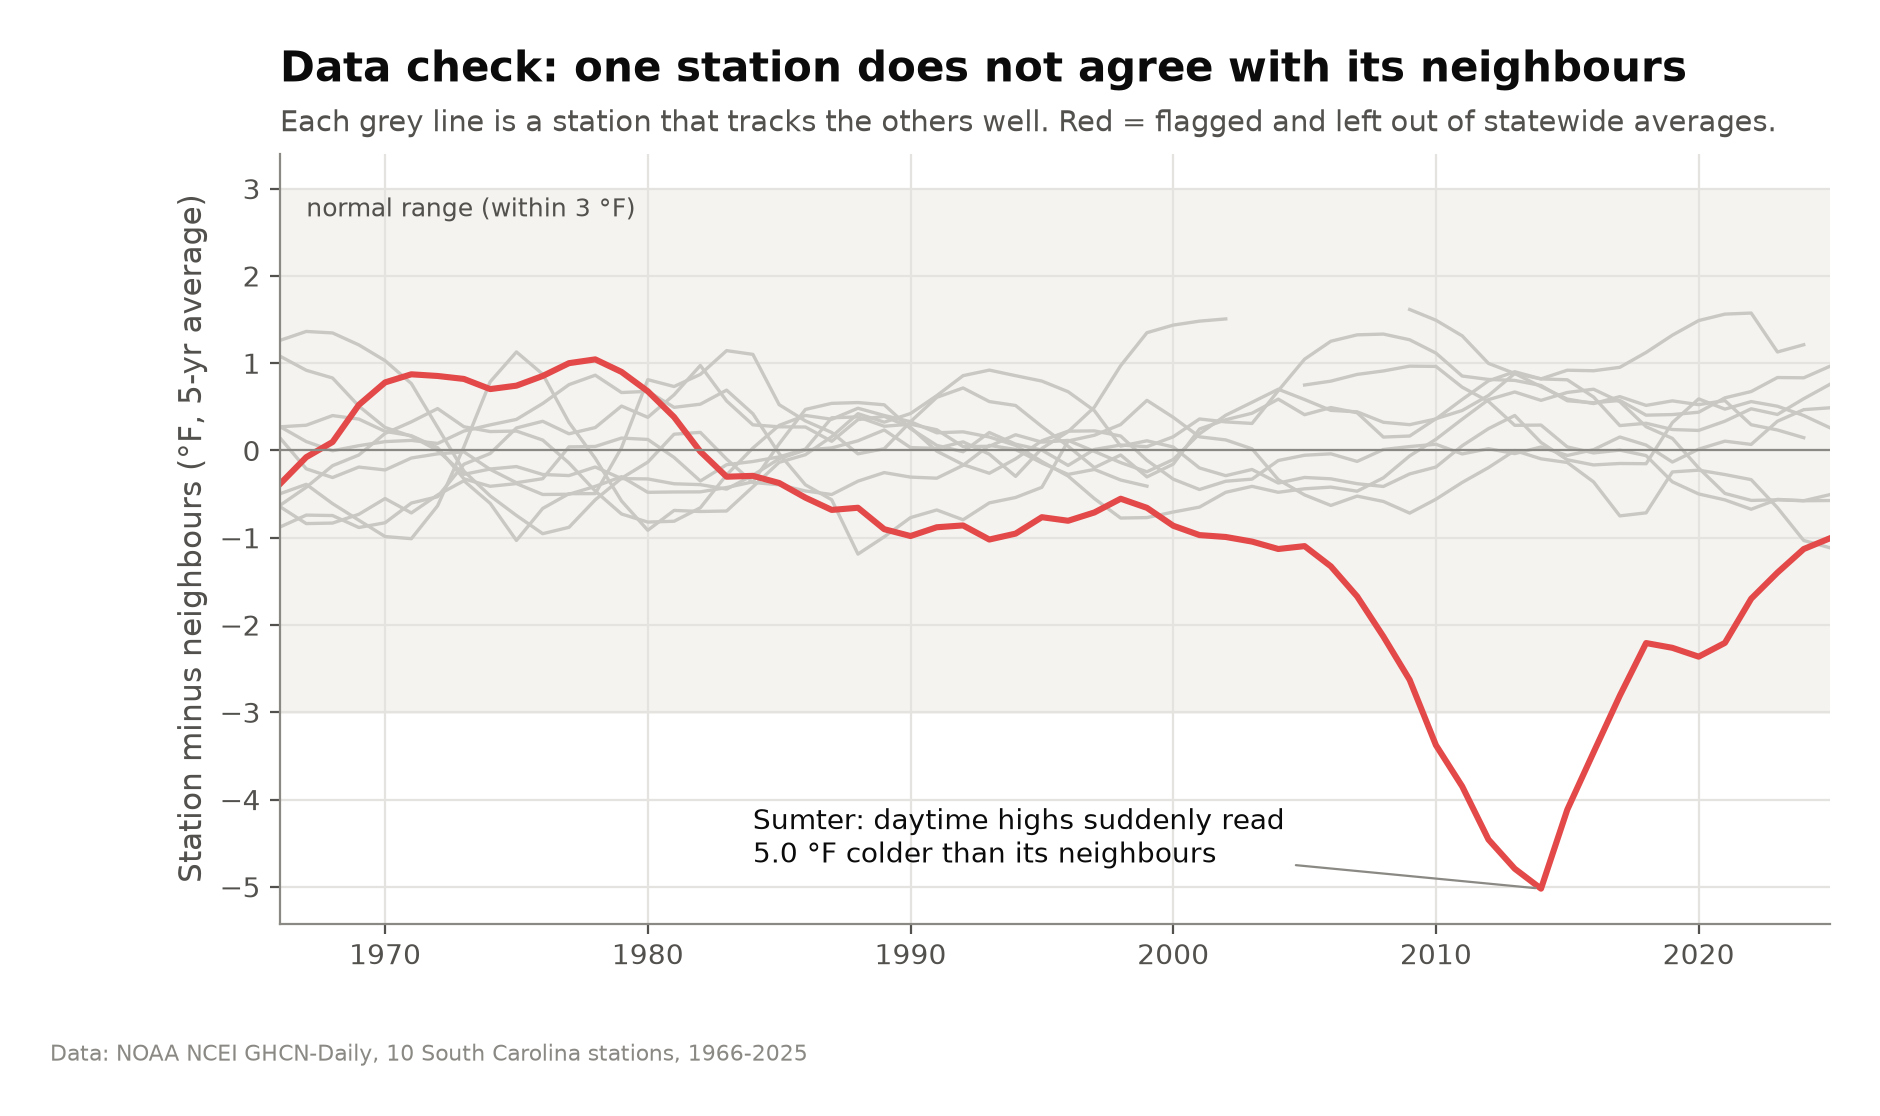

In [6]:
display(Image("figures/fig01_station_map.png", width=900))
display(Image("figures/fig02_data_quality_check.png", width=900))

**Sumter** reads up to 5 °F too cold around 2010–2015, so it is left out of every statewide temperature average (still shown in grey).

## The three angles – and why they make sense

| Angle | Question | Why it makes sense |
|---|---|---|
| **1. Where** | Which South Carolina city has warmed the most? | Local vs. statewide; ranks cities for local planning (the assignment's example). |
| **2. When** | Day or night? Which season? | The average hides *how* it warms; night vs. day points to causes like city heat. |
| **3. What people feel** | Are extreme days more common? | People feel thresholds – heat, warm nights, frost, floods. Also tests rain. |

Together: **the average → its timing → the extremes**.

## Angle 1 – Where is South Carolina warming the most?

In [7]:
a1 = angle1_where.main()
display(Markdown(f"**Statewide:** {a1['statewide_f_per_decade']:+.2f} °F per decade "
                 f"(± {a1['statewide_ci95']:.2f}), about {a1['statewide_f_per_decade'] * 6:+.1f} °F over 60 years. "
                 f"**Fastest:** {a1['fastest_city']} ({a1['fastest_rate']:+.2f} °F/decade)."))

  saved figures/fig03_statewide_warming.png


  saved figures/fig04_warming_rate_by_city.png


  saved figures/fig05_warming_map.png


  saved figures/fig06_warming_stripes.png
 rank                   city  warming_f_per_decade  ci95  p_value  period_change_f
    1               Columbia                  0.58  0.17     0.00             1.62
    2 Greenville-Spartanburg                  0.56  0.14     0.00             1.77
    3               Beaufort                  0.56  0.17     0.00             1.40
    4   Charleston (Airport)                  0.56  0.15     0.00             1.31
    5                Clemson                  0.49  0.17     0.00             1.89
    6  Charleston (Downtown)                  0.46  0.14     0.00             1.39
    7              Rock Hill                  0.43  0.16     0.00             1.40
    8               Florence                  0.41  0.20     0.00             0.87
    9               Anderson                  0.33  0.17     0.00             0.79
   10                 Sumter                 -0.06  0.23     0.61            -0.25


**Statewide:** +0.49 °F per decade (± 0.14), about +2.9 °F over 60 years. **Fastest:** Columbia (+0.58 °F/decade).

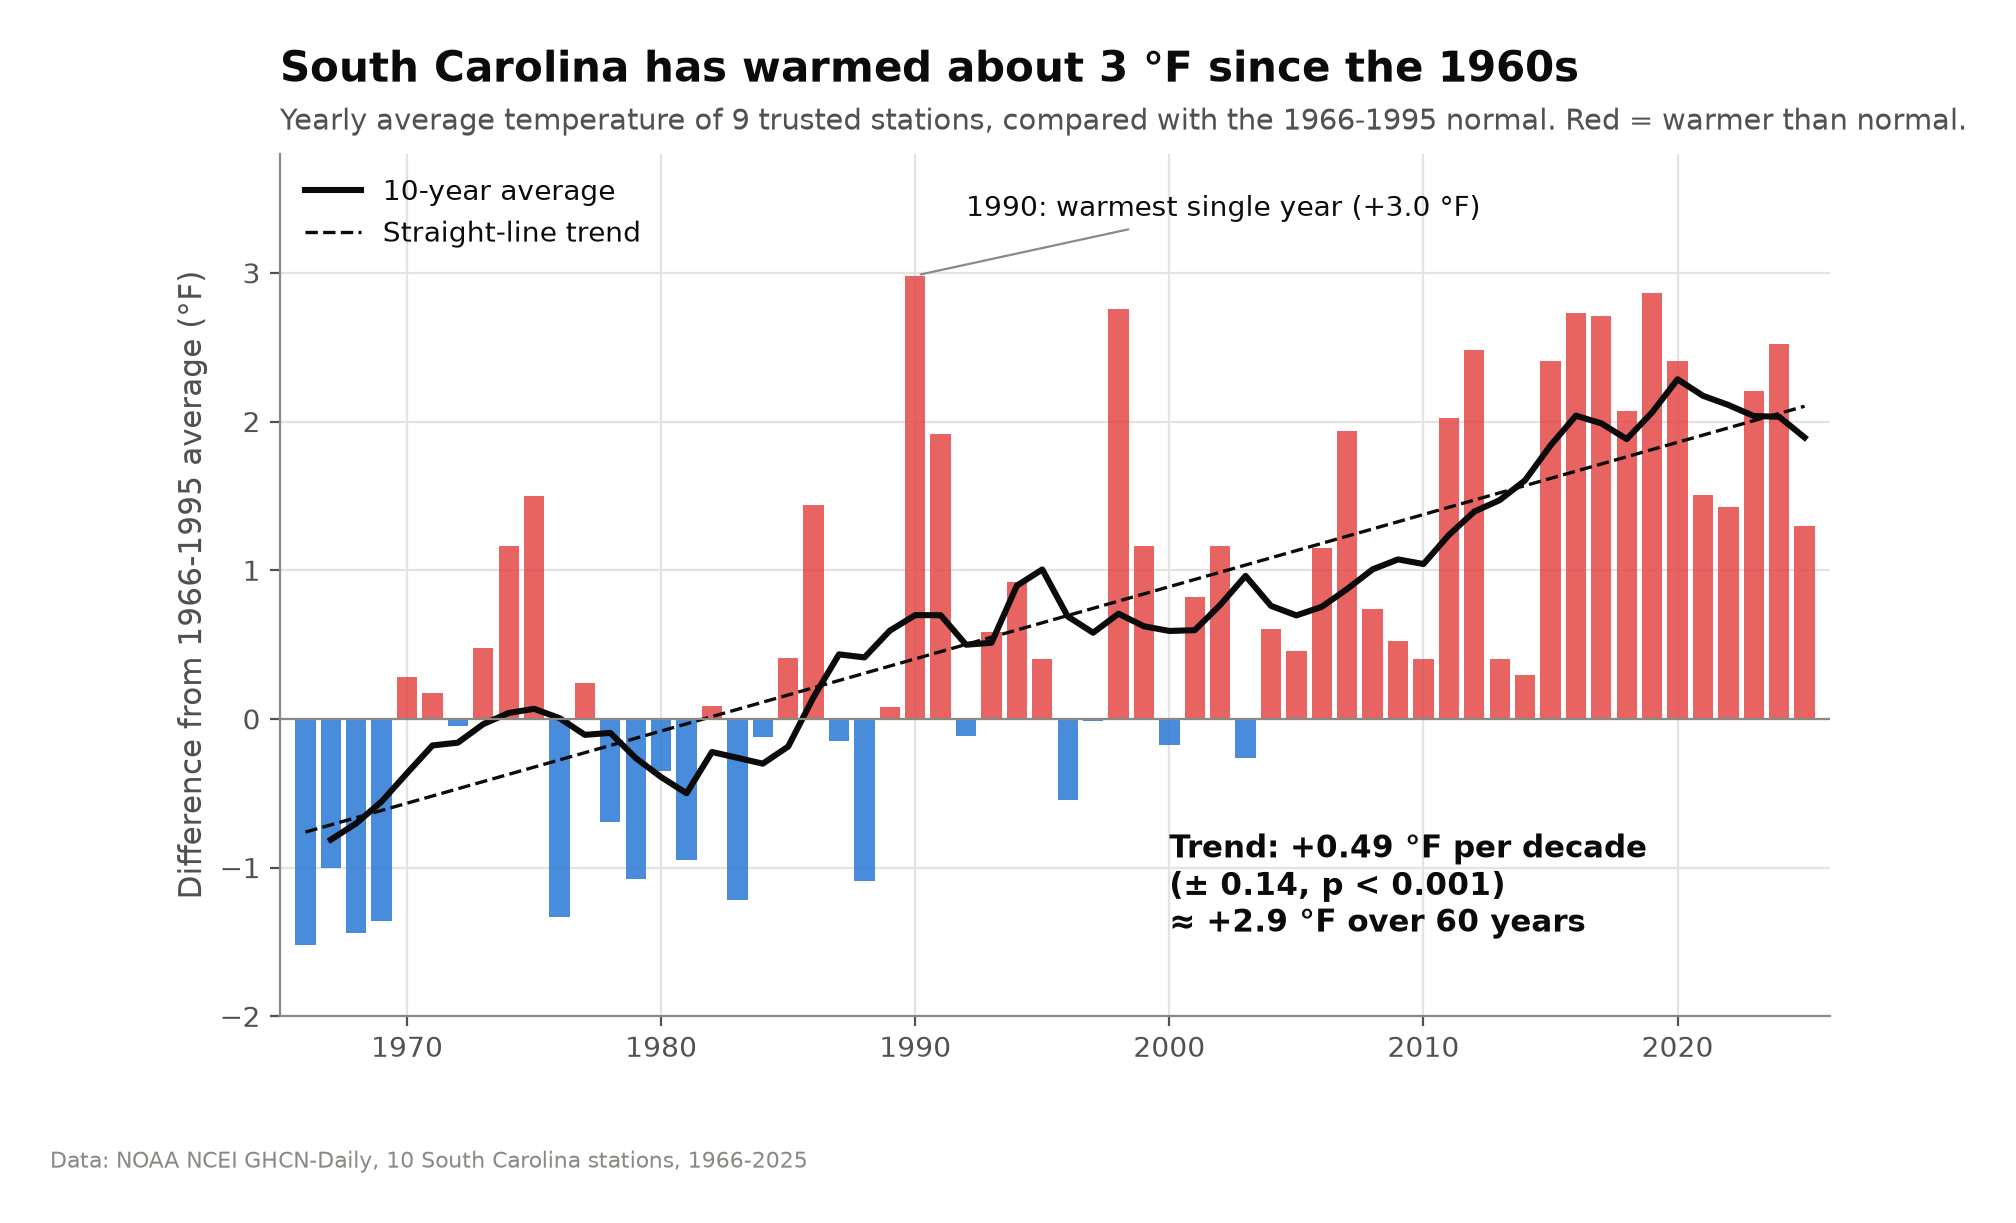

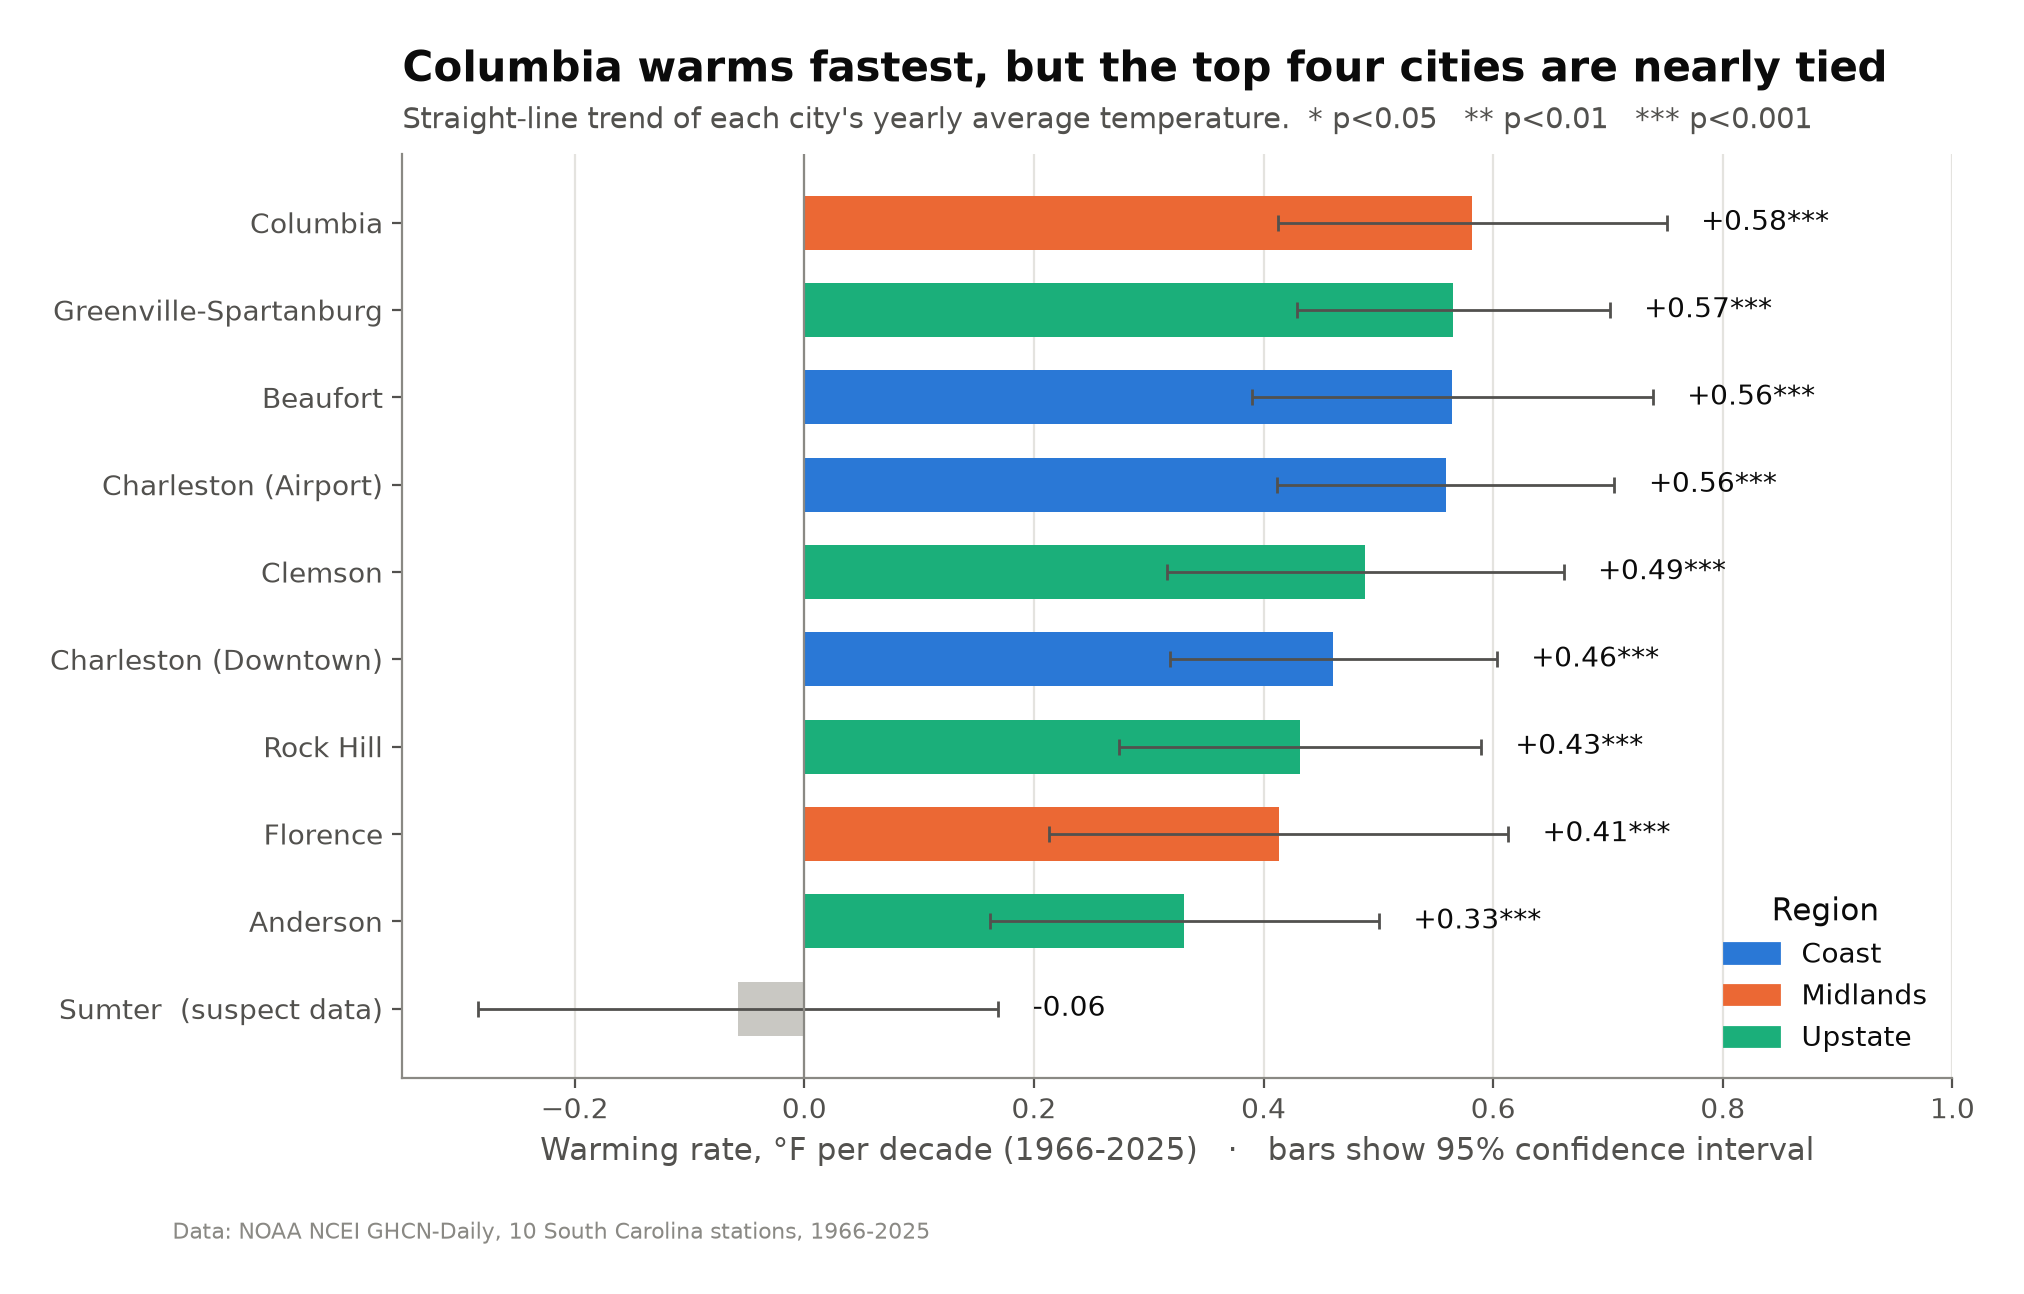

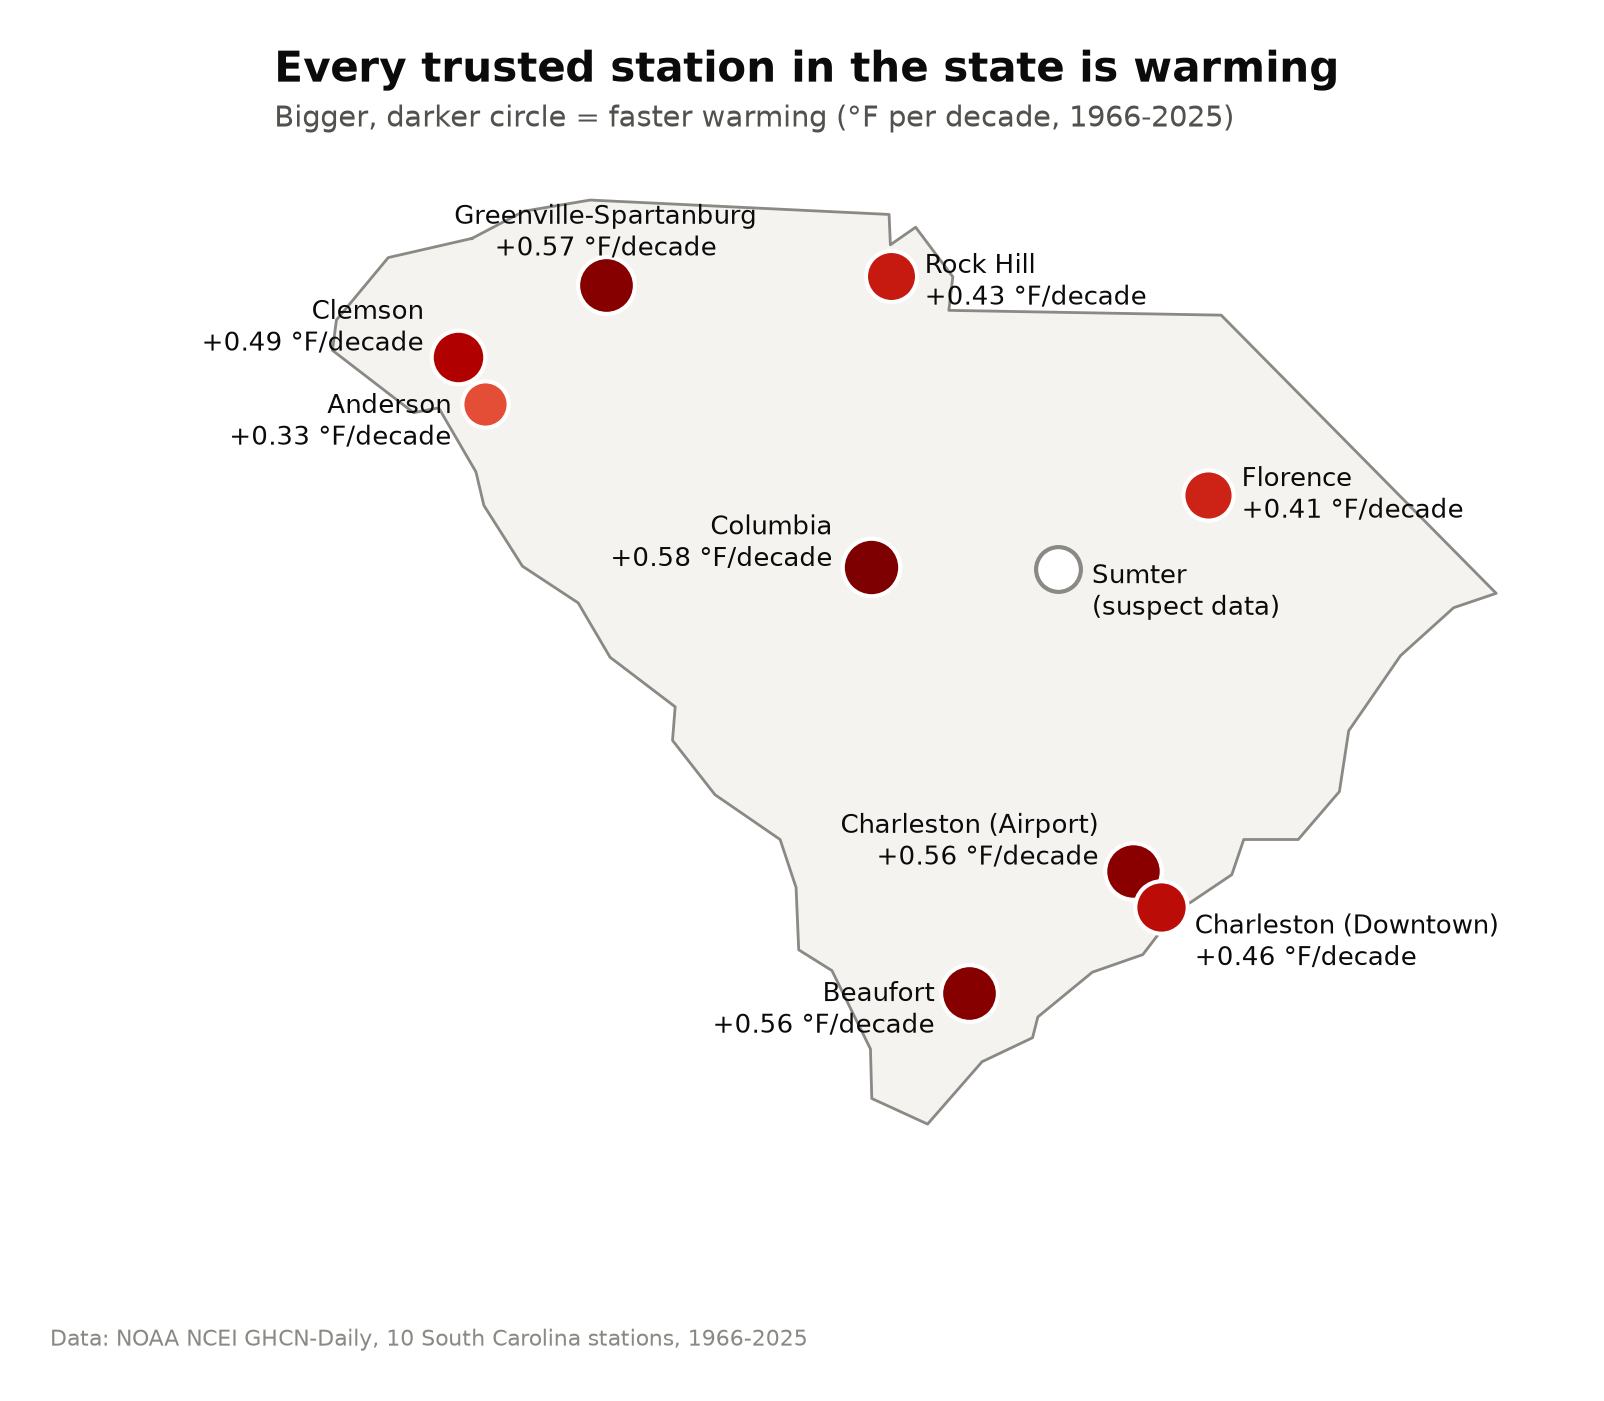

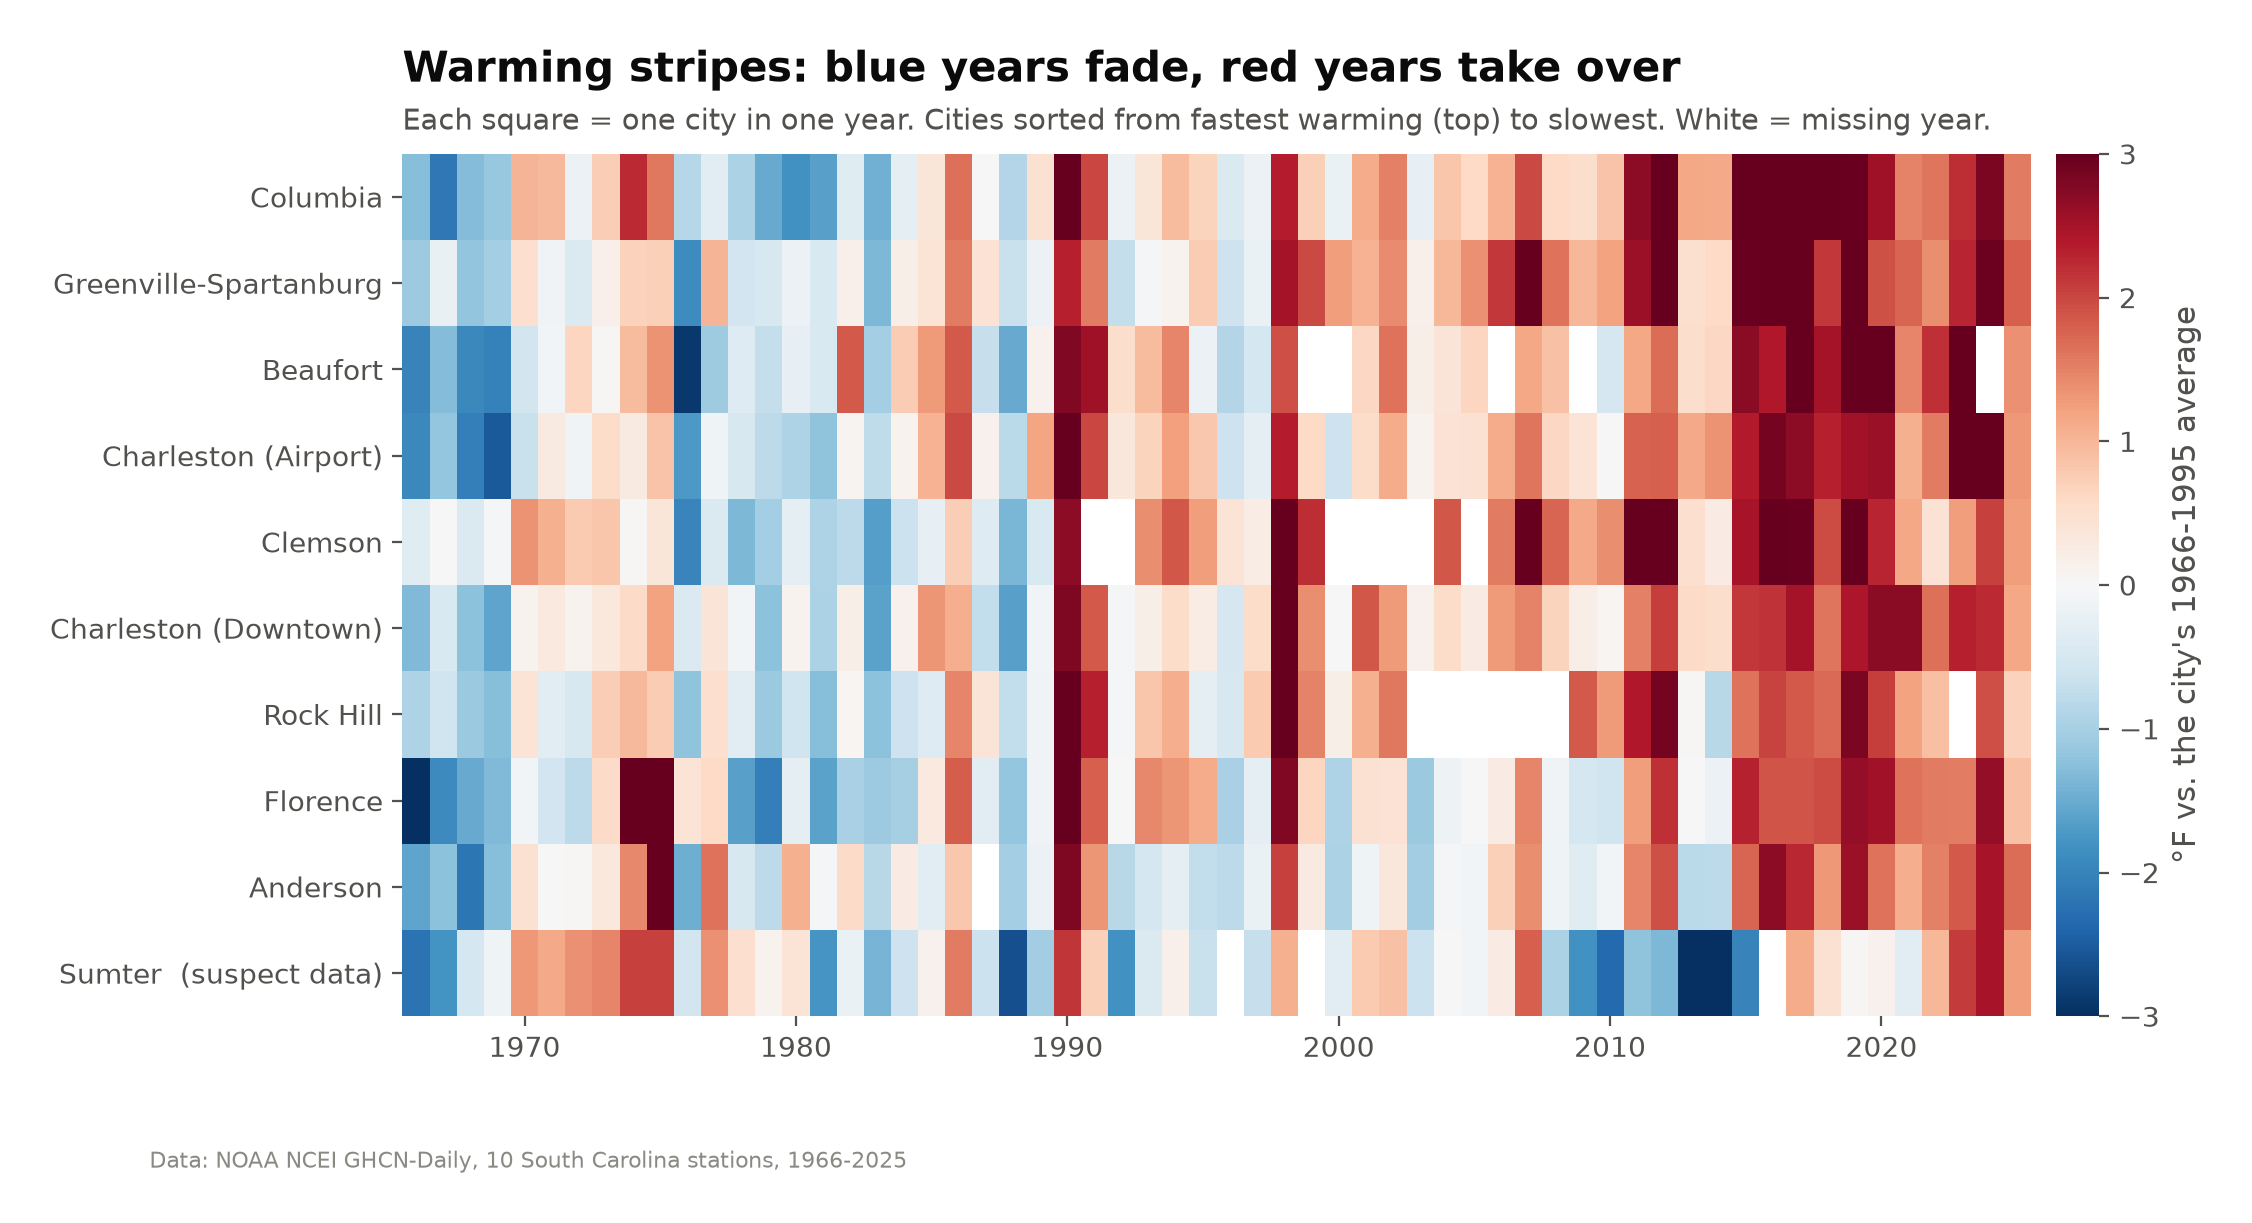

In [8]:
display(Image("figures/fig03_statewide_warming.png", width=900))
display(Image("figures/fig04_warming_rate_by_city.png", width=900))
display(Image("figures/fig05_warming_map.png", width=900))
display(Image("figures/fig06_warming_stripes.png", width=900))

**Answer:** Columbia warmed fastest (+0.58 °F/decade), but the top four cities
are statistically tied – and **every** trusted station warmed significantly
(p < 0.001). Warming is statewide, not local.

## Angle 2 – When: day or night, and which season?

In [9]:
a2 = angle2_when.main()
display(Markdown(f"**Nights** {a2['avg_lows_f_per_decade']:+.2f} vs **days** {a2['avg_highs_f_per_decade']:+.2f} °F/decade. "
                 f"Winter warms {a2['winter_vs_rest_ratio']:.1f}× faster than the other seasons."))

  saved figures/fig07_day_vs_night_by_city.png


  saved figures/fig08_warming_by_season.png
                  city   region  suspect_station  highs_f_per_decade  highs_p  lows_f_per_decade  lows_p  nights_minus_days
  Charleston (Airport)    Coast            False                0.48     0.00               0.64    0.00               0.16
 Charleston (Downtown)    Coast            False                0.21     0.01               0.71    0.00               0.50
              Beaufort    Coast            False                0.62     0.00               0.51    0.00              -0.11
              Columbia Midlands            False                0.36     0.00               0.81    0.00               0.45
              Florence Midlands            False                0.44     0.00               0.38    0.00              -0.06
                Sumter Midlands             True               -0.26     0.03               0.16    0.19               0.42
Greenville-Spartanburg  Upstate            False                0.53     0.00           

**Nights** +0.55 vs **days** +0.43 °F/decade. Winter warms 1.7× faster than the other seasons.

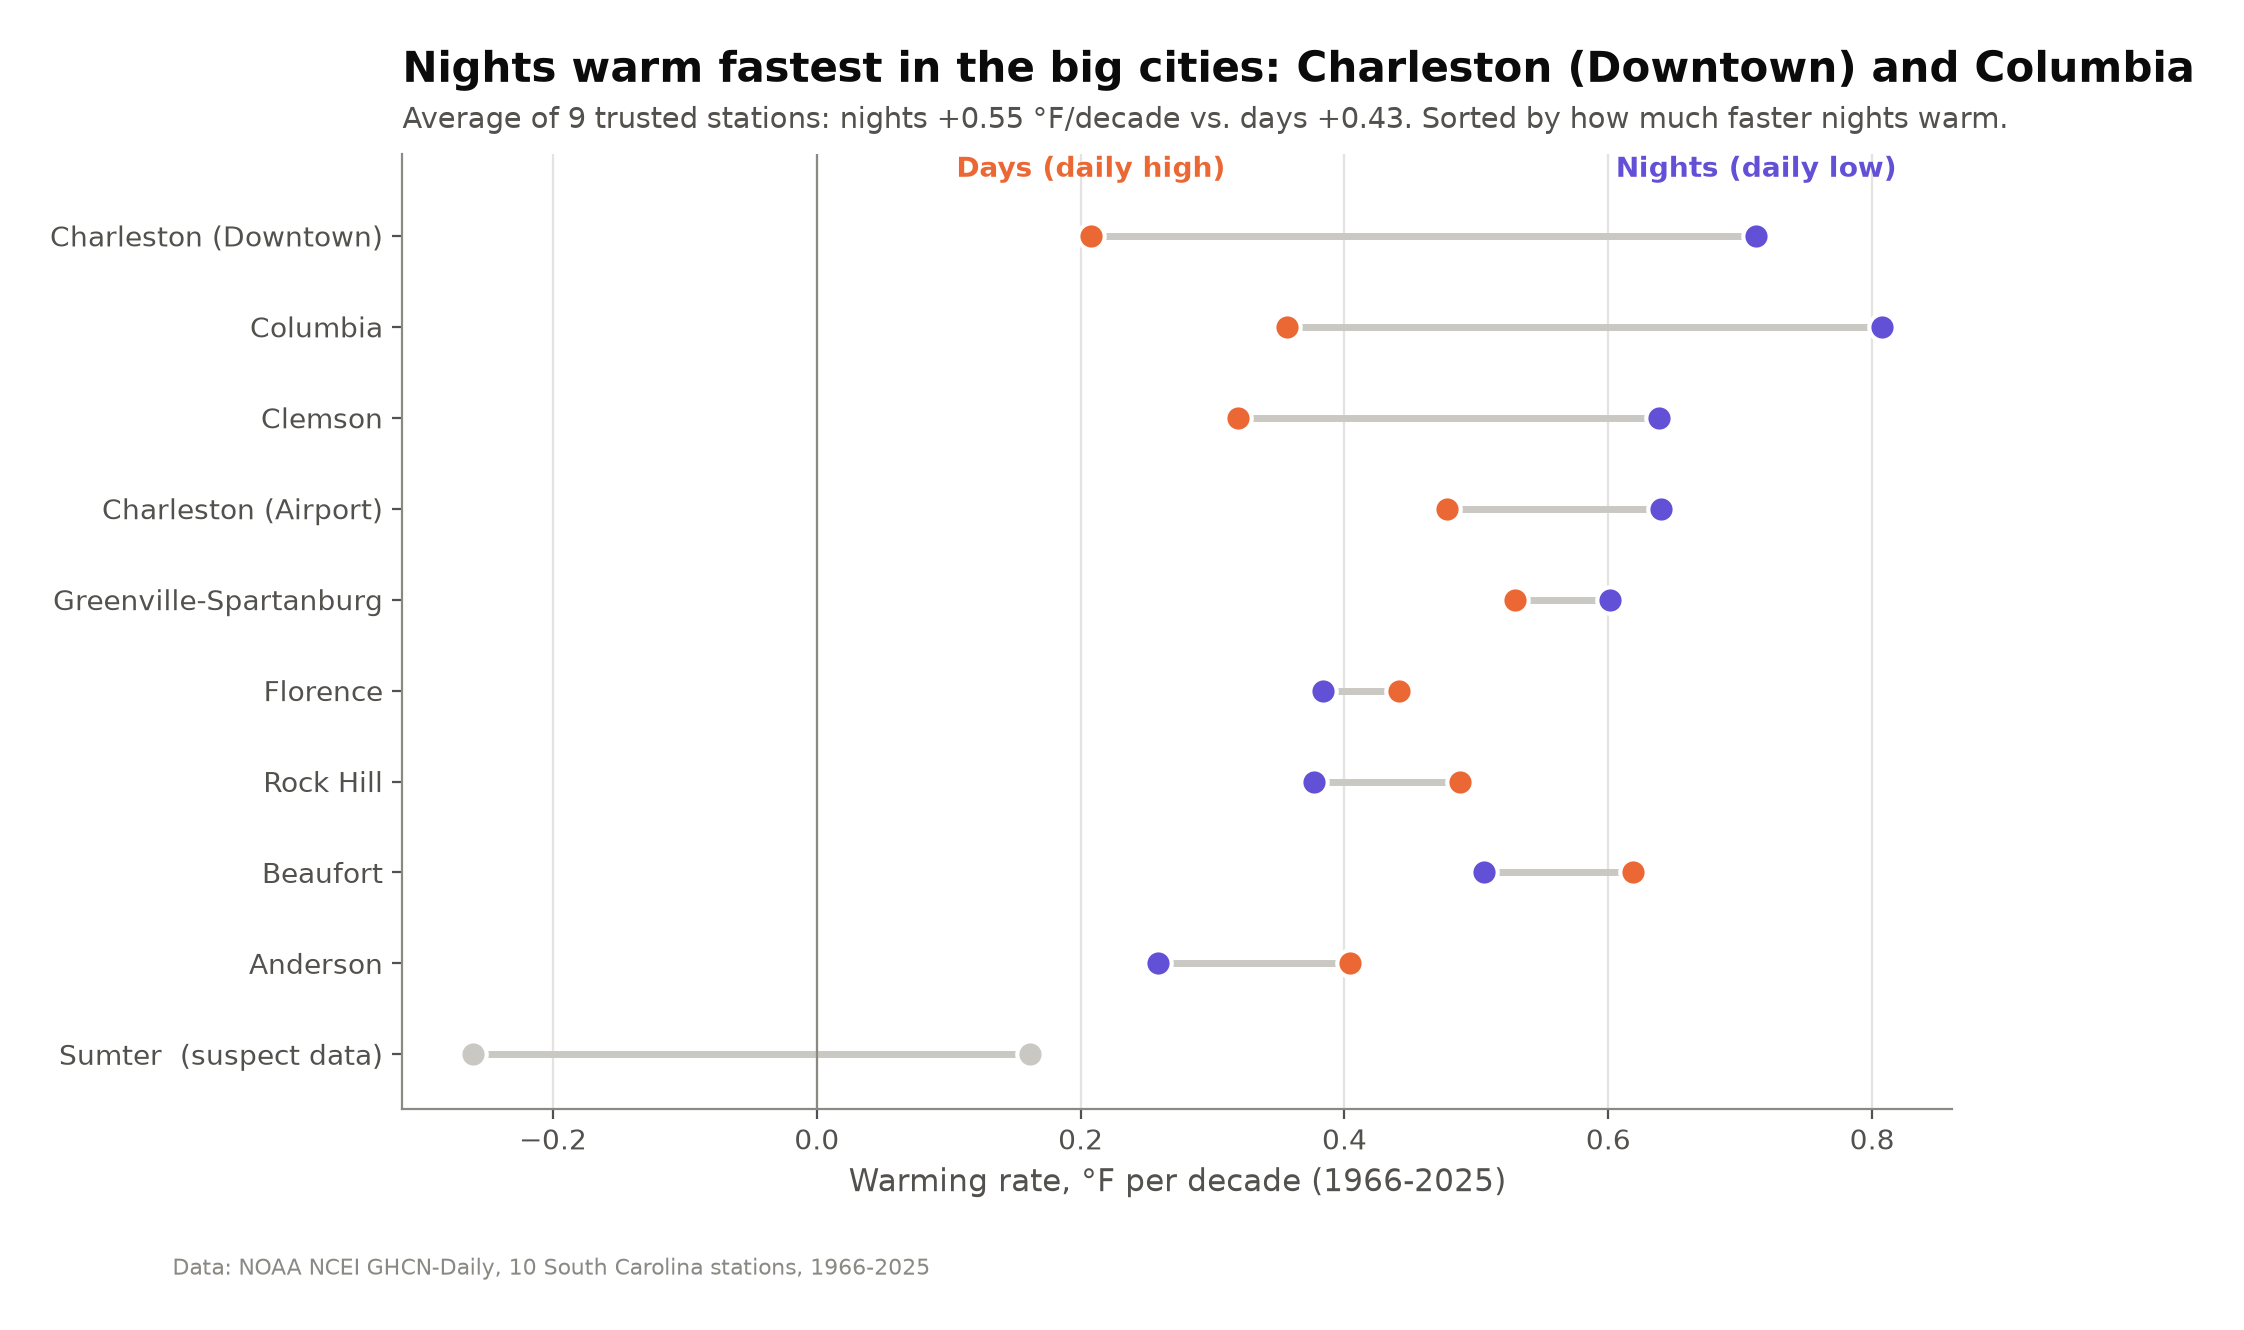

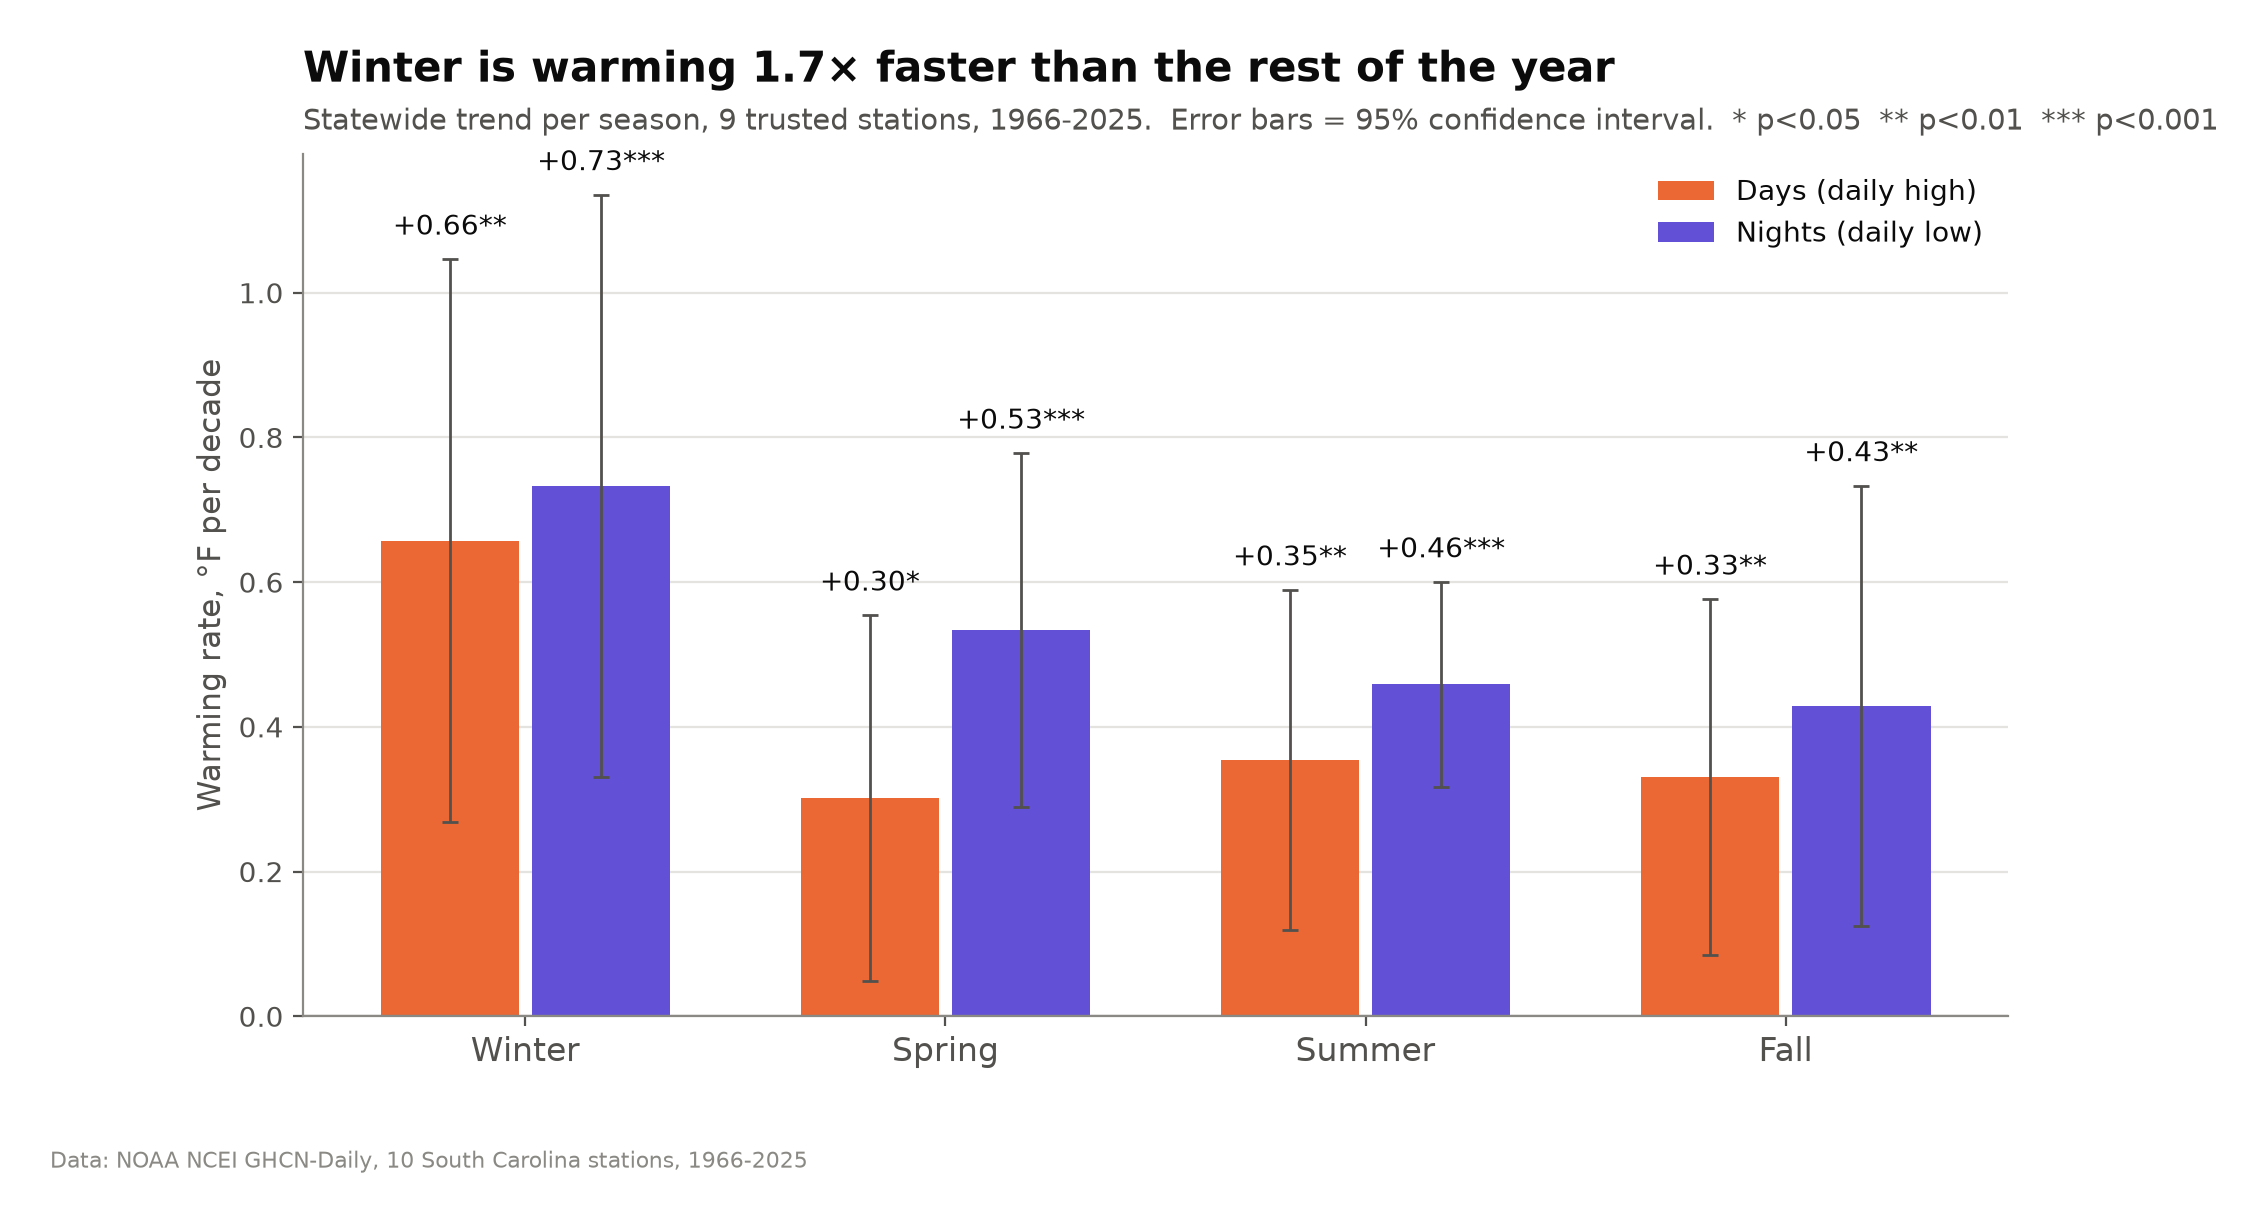

In [10]:
display(Image("figures/fig07_day_vs_night_by_city.png", width=900))
display(Image("figures/fig08_warming_by_season.png", width=900))

**Answer:** the warming is strongest in **winter** and at **night**. The night-time
gap is biggest in downtown Charleston and Columbia – the urban heat island effect.

## Angle 3 – What do people feel? Extreme days

In [11]:
a3 = angle3_extremes.main()
pd.read_csv(config.RESULTS_DIR / "angle3_extremes_scorecard.csv")[
    ["metric", "mean_1966_1995", "mean_1996_2025", "pct_change", "p_value", "significant"]]

  saved figures/fig09_hot_days_and_warm_nights.png


  saved figures/fig10_freeze_season.png


  saved figures/fig11_heavy_rain.png


  saved figures/fig12_extremes_scorecard.png
                   metric            column    unit  mean_1966_1995  mean_1996_2025    change  pct_change  trend_per_decade  p_value  significant
  Hot days (high ≥ 95 °F)          hot_days days/yr           13.40           16.17  2.77e+00       20.72              1.41     0.05         True
Warm nights (low ≥ 75 °F)       warm_nights days/yr           15.58           22.93  7.35e+00       47.20              2.78     0.00         True
Freeze days (low ≤ 32 °F)       freeze_days days/yr           46.04           37.69 -8.35e+00      -18.14             -3.12     0.00         True
       Freeze-free season  freeze_free_days    days          238.05          247.33  9.28e+00        3.90              3.43     0.00         True
        Yearly rain total     rain_total_in  inches           48.80           46.09 -2.72e+00       -5.57             -0.45     0.37        False
 Heavy rain days (≥ 2 in)   heavy_rain_days days/yr            3.06            

,metric,mean_1966_1995,mean_1996_2025,pct_change,p_value,significant
0,Hot days (high ≥ 95 °F),13.40,16.17,20.72,0.05,True
1,Warm nights (low ≥ 75 °F),15.58,22.93,47.20,0.00,True
2,Freeze days (low ≤ 32 °F),46.04,37.69,-18.14,0.00,True
3,Freeze-free season,238.05,247.33,3.90,0.00,True
4,Yearly rain total,48.80,46.09,-5.57,0.37,False
5,Heavy rain days (≥ 2 in),3.06,3.05,-0.23,0.56,False
6,Wettest day of the year,3.46,3.50,1.21,0.53,False
7,Longest dry spell,19.59,20.14,2.84,0.86,False


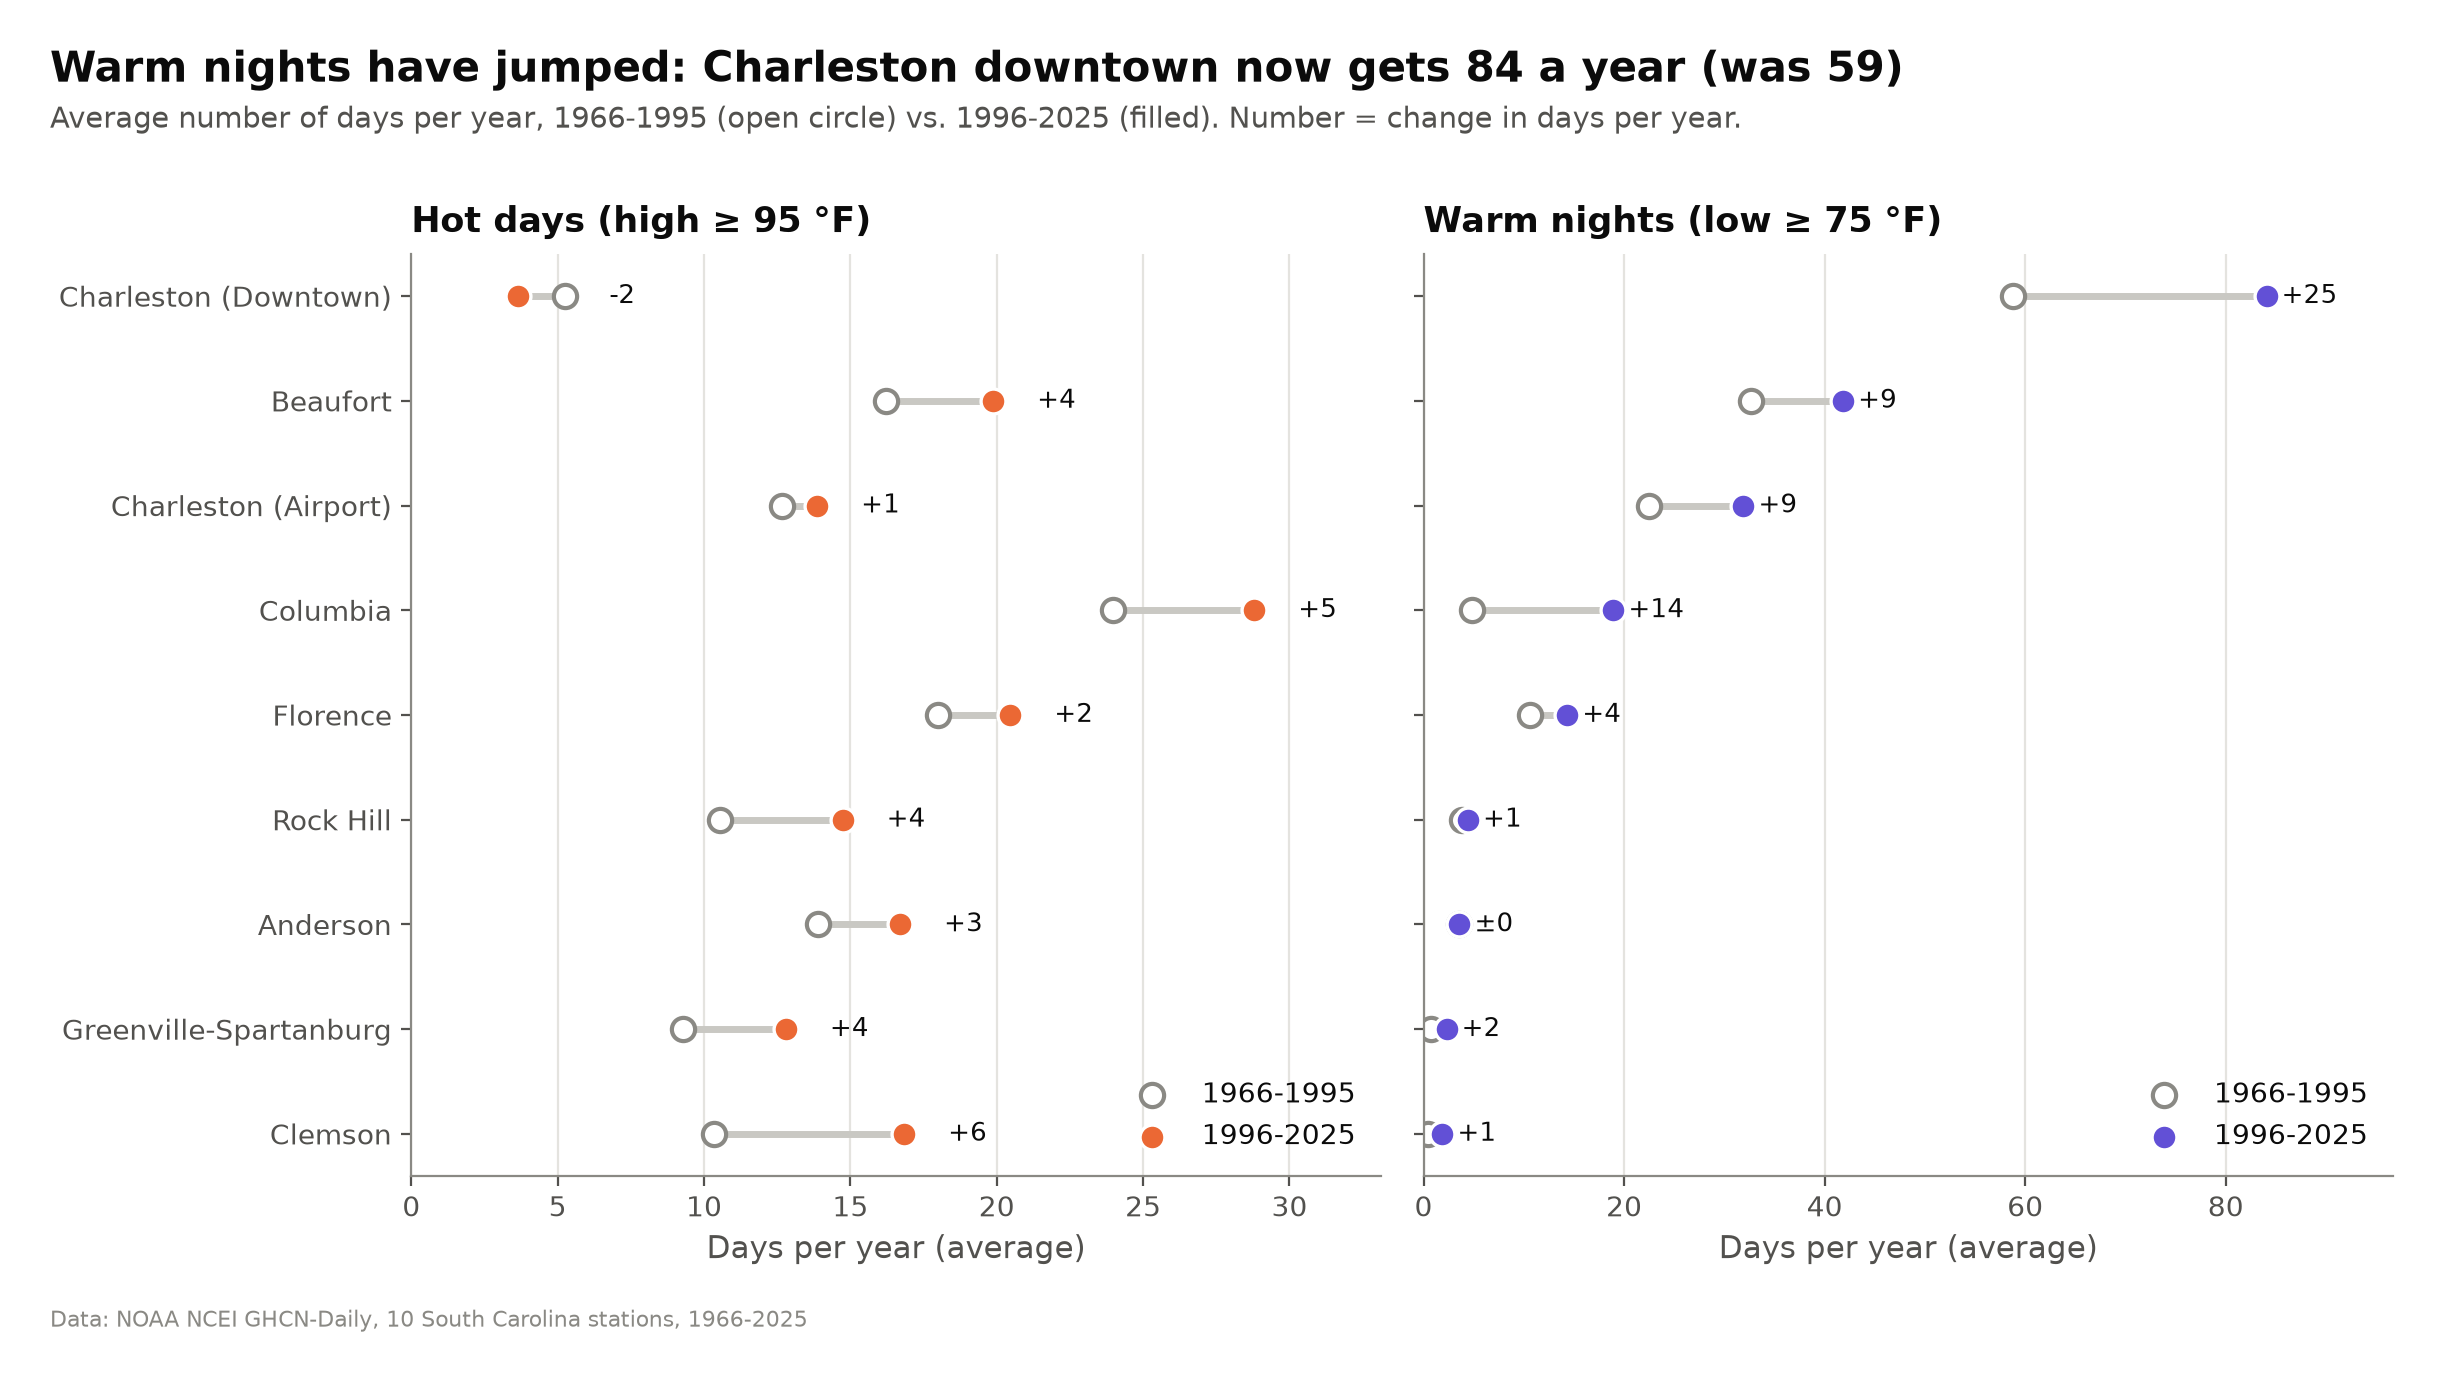

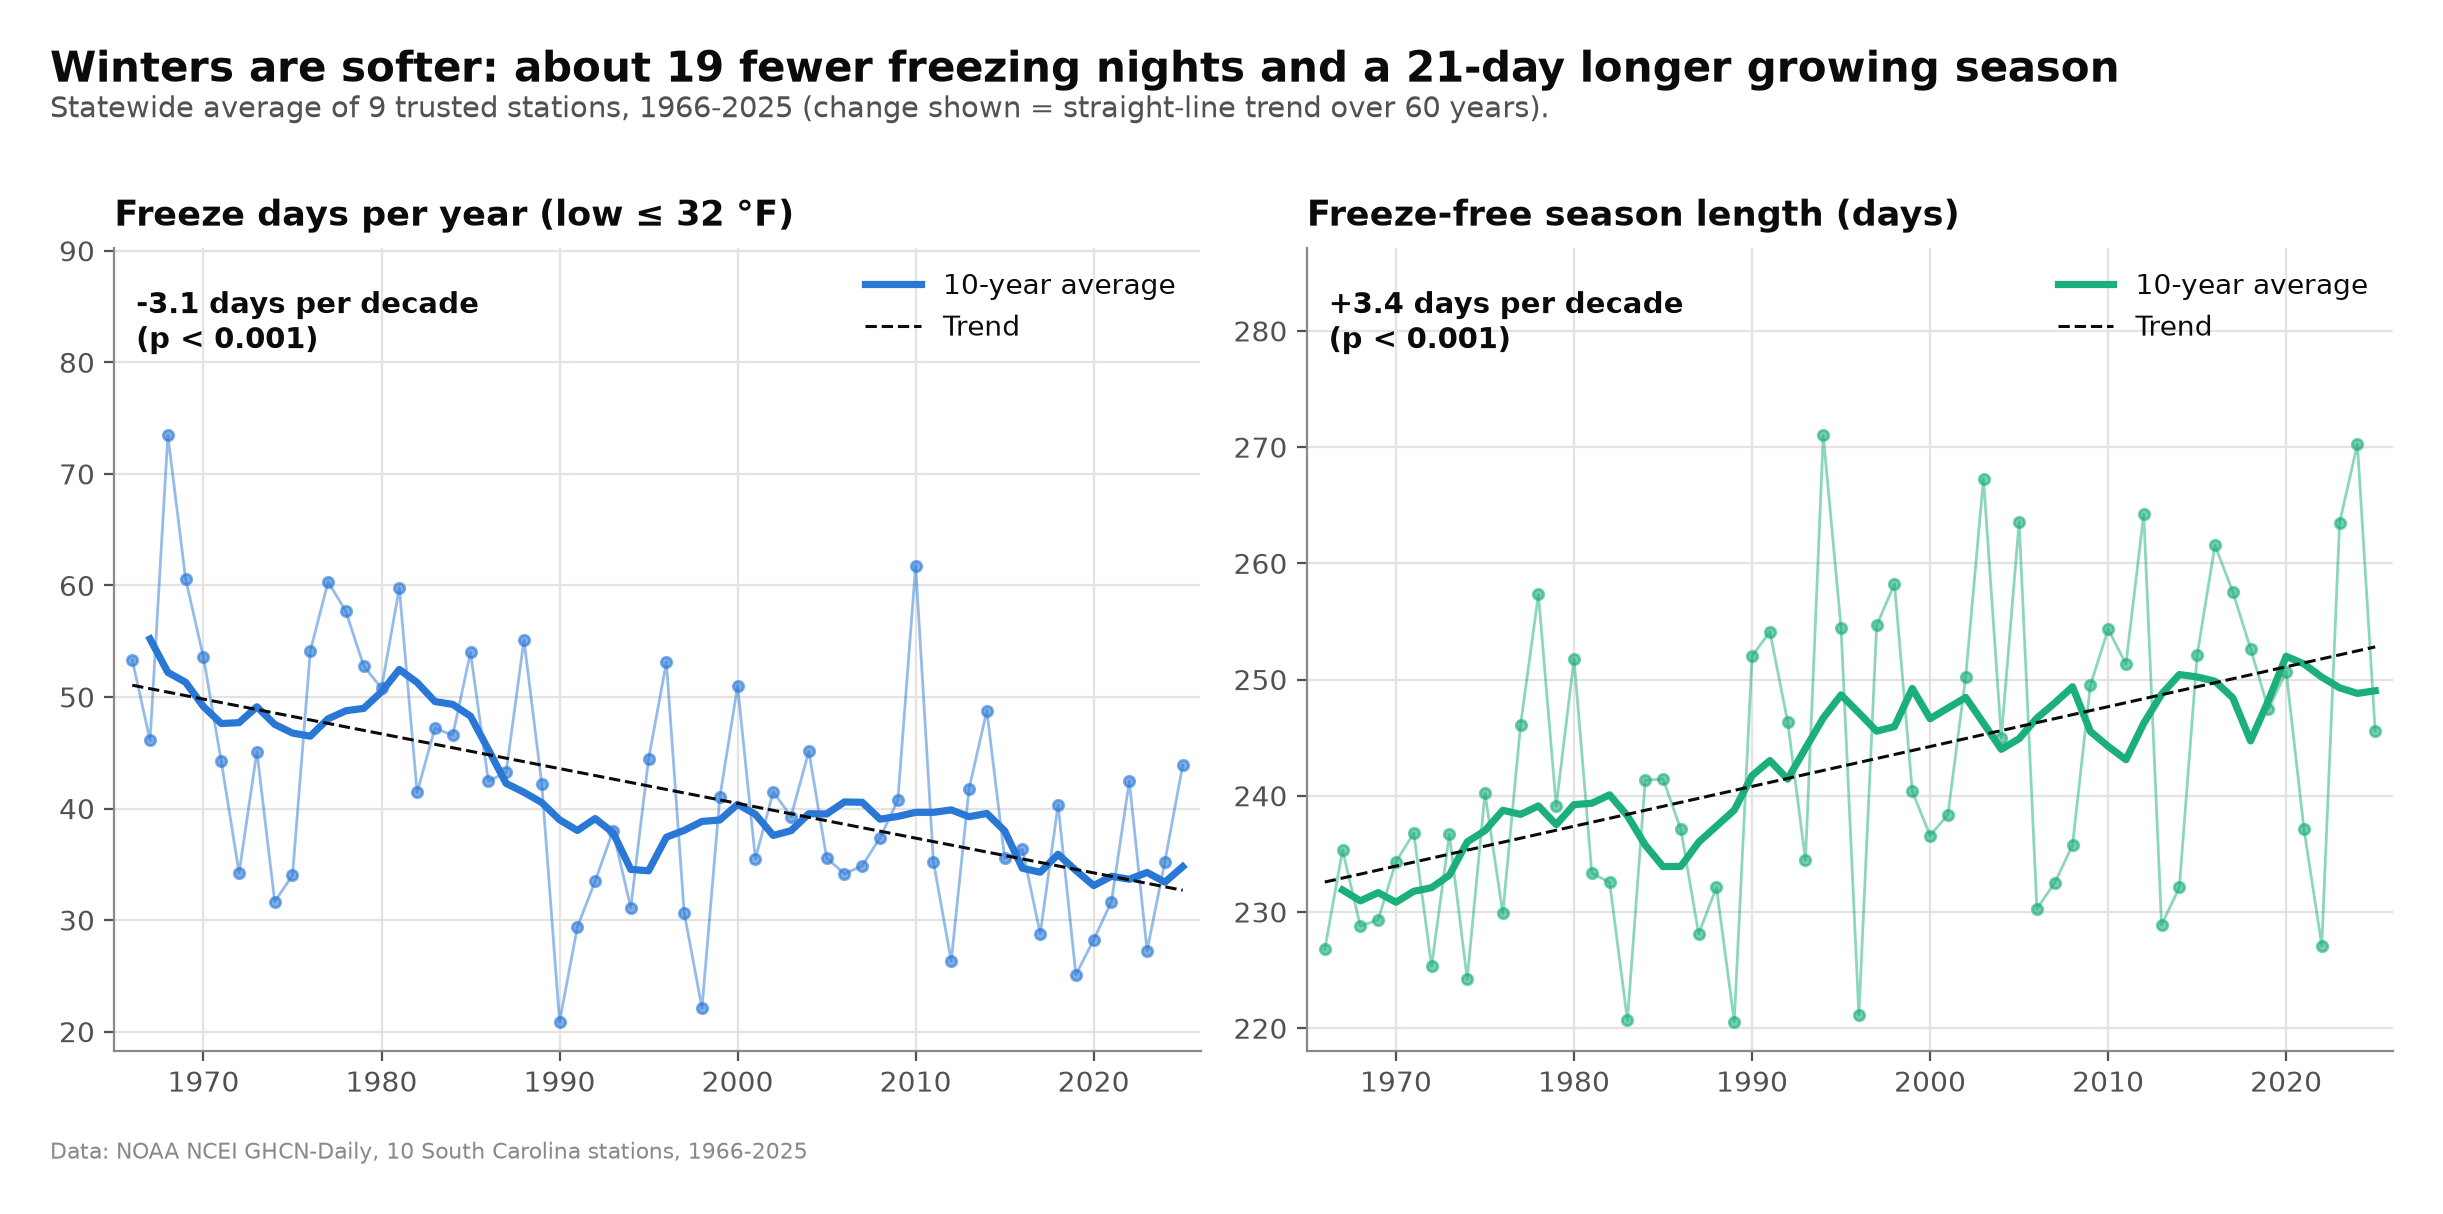

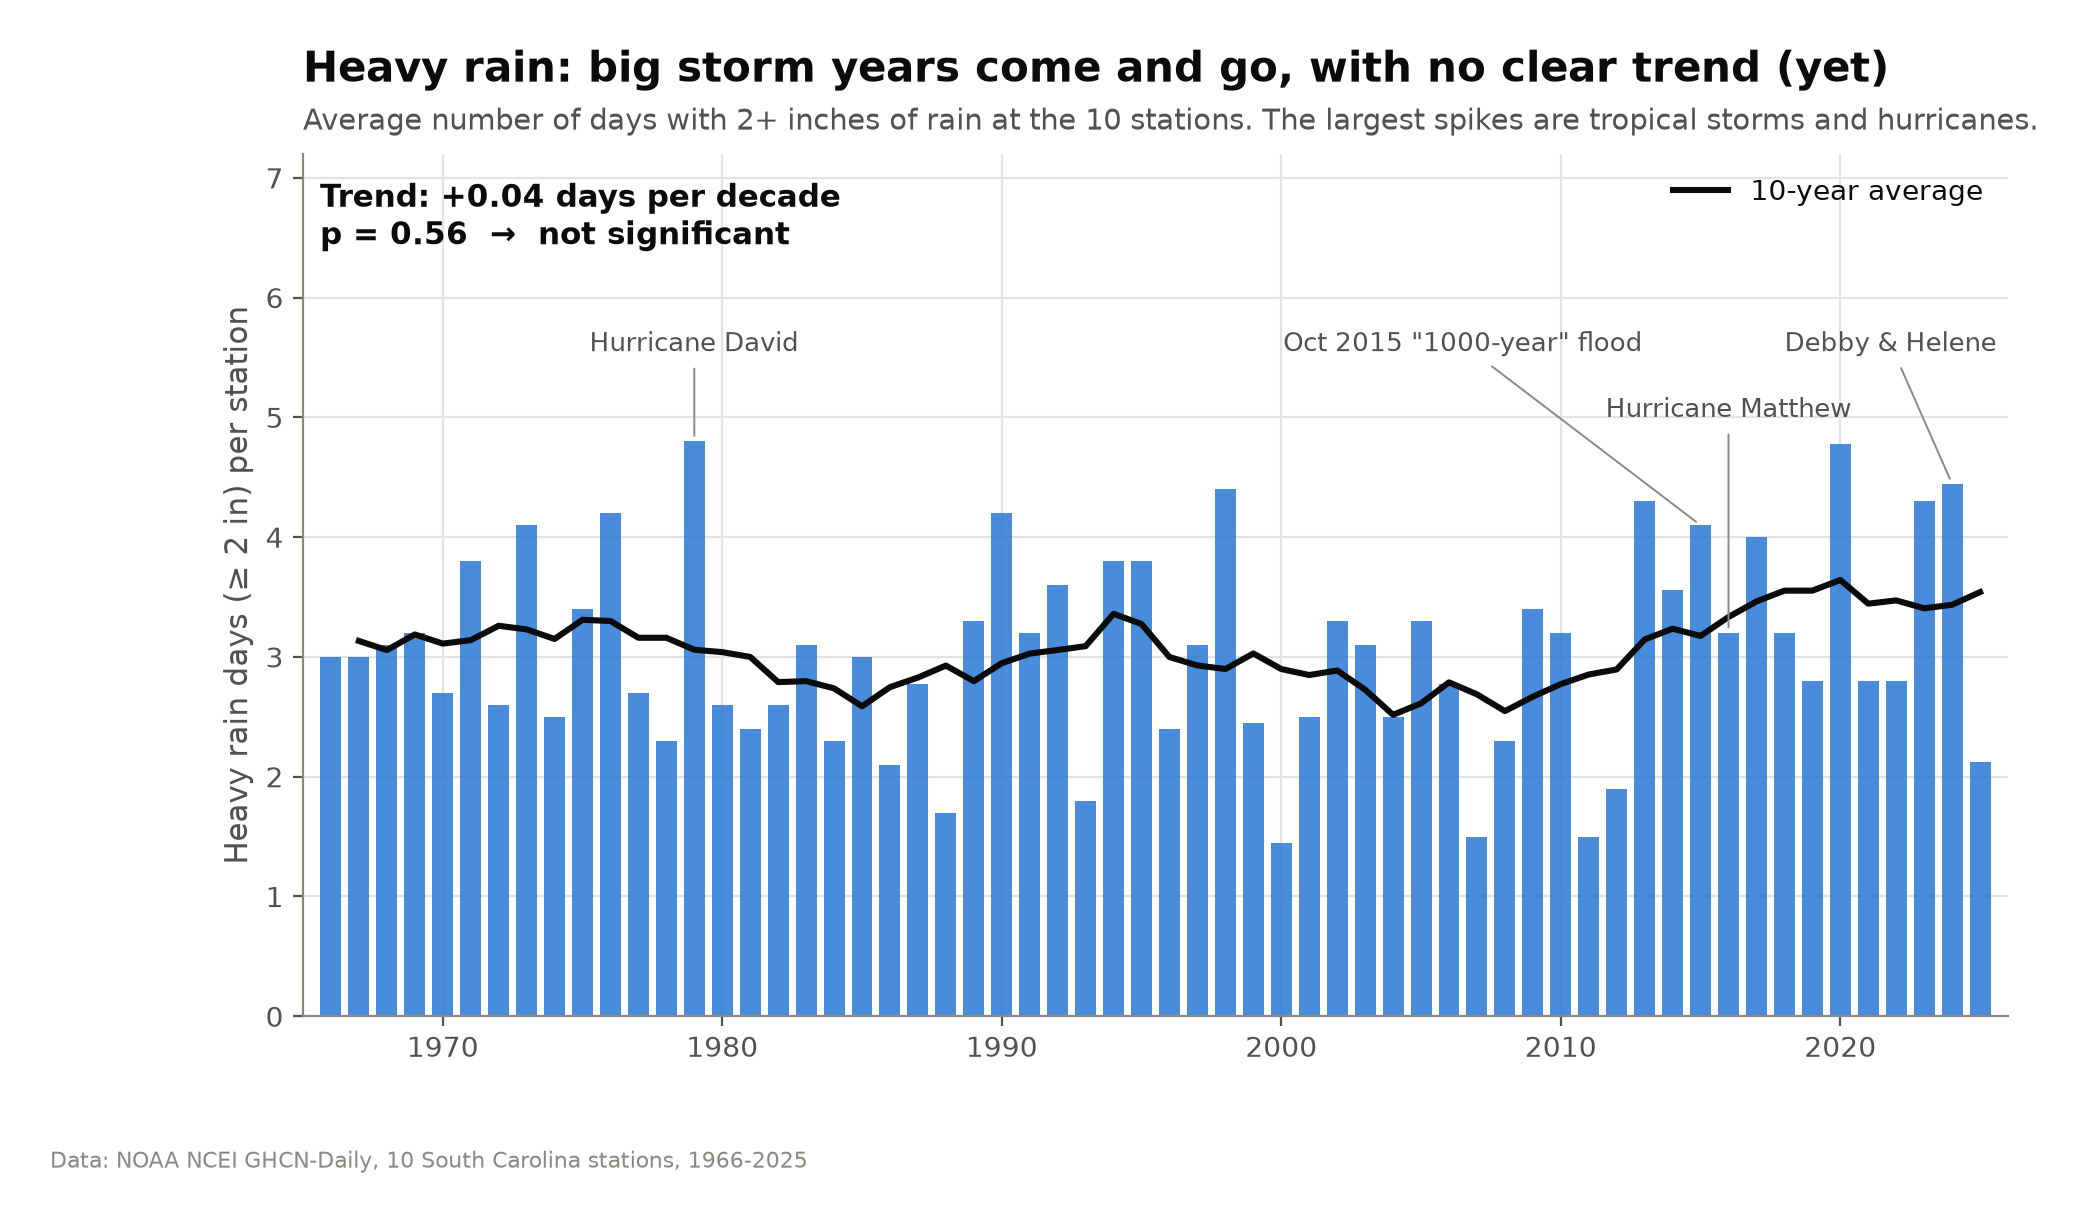

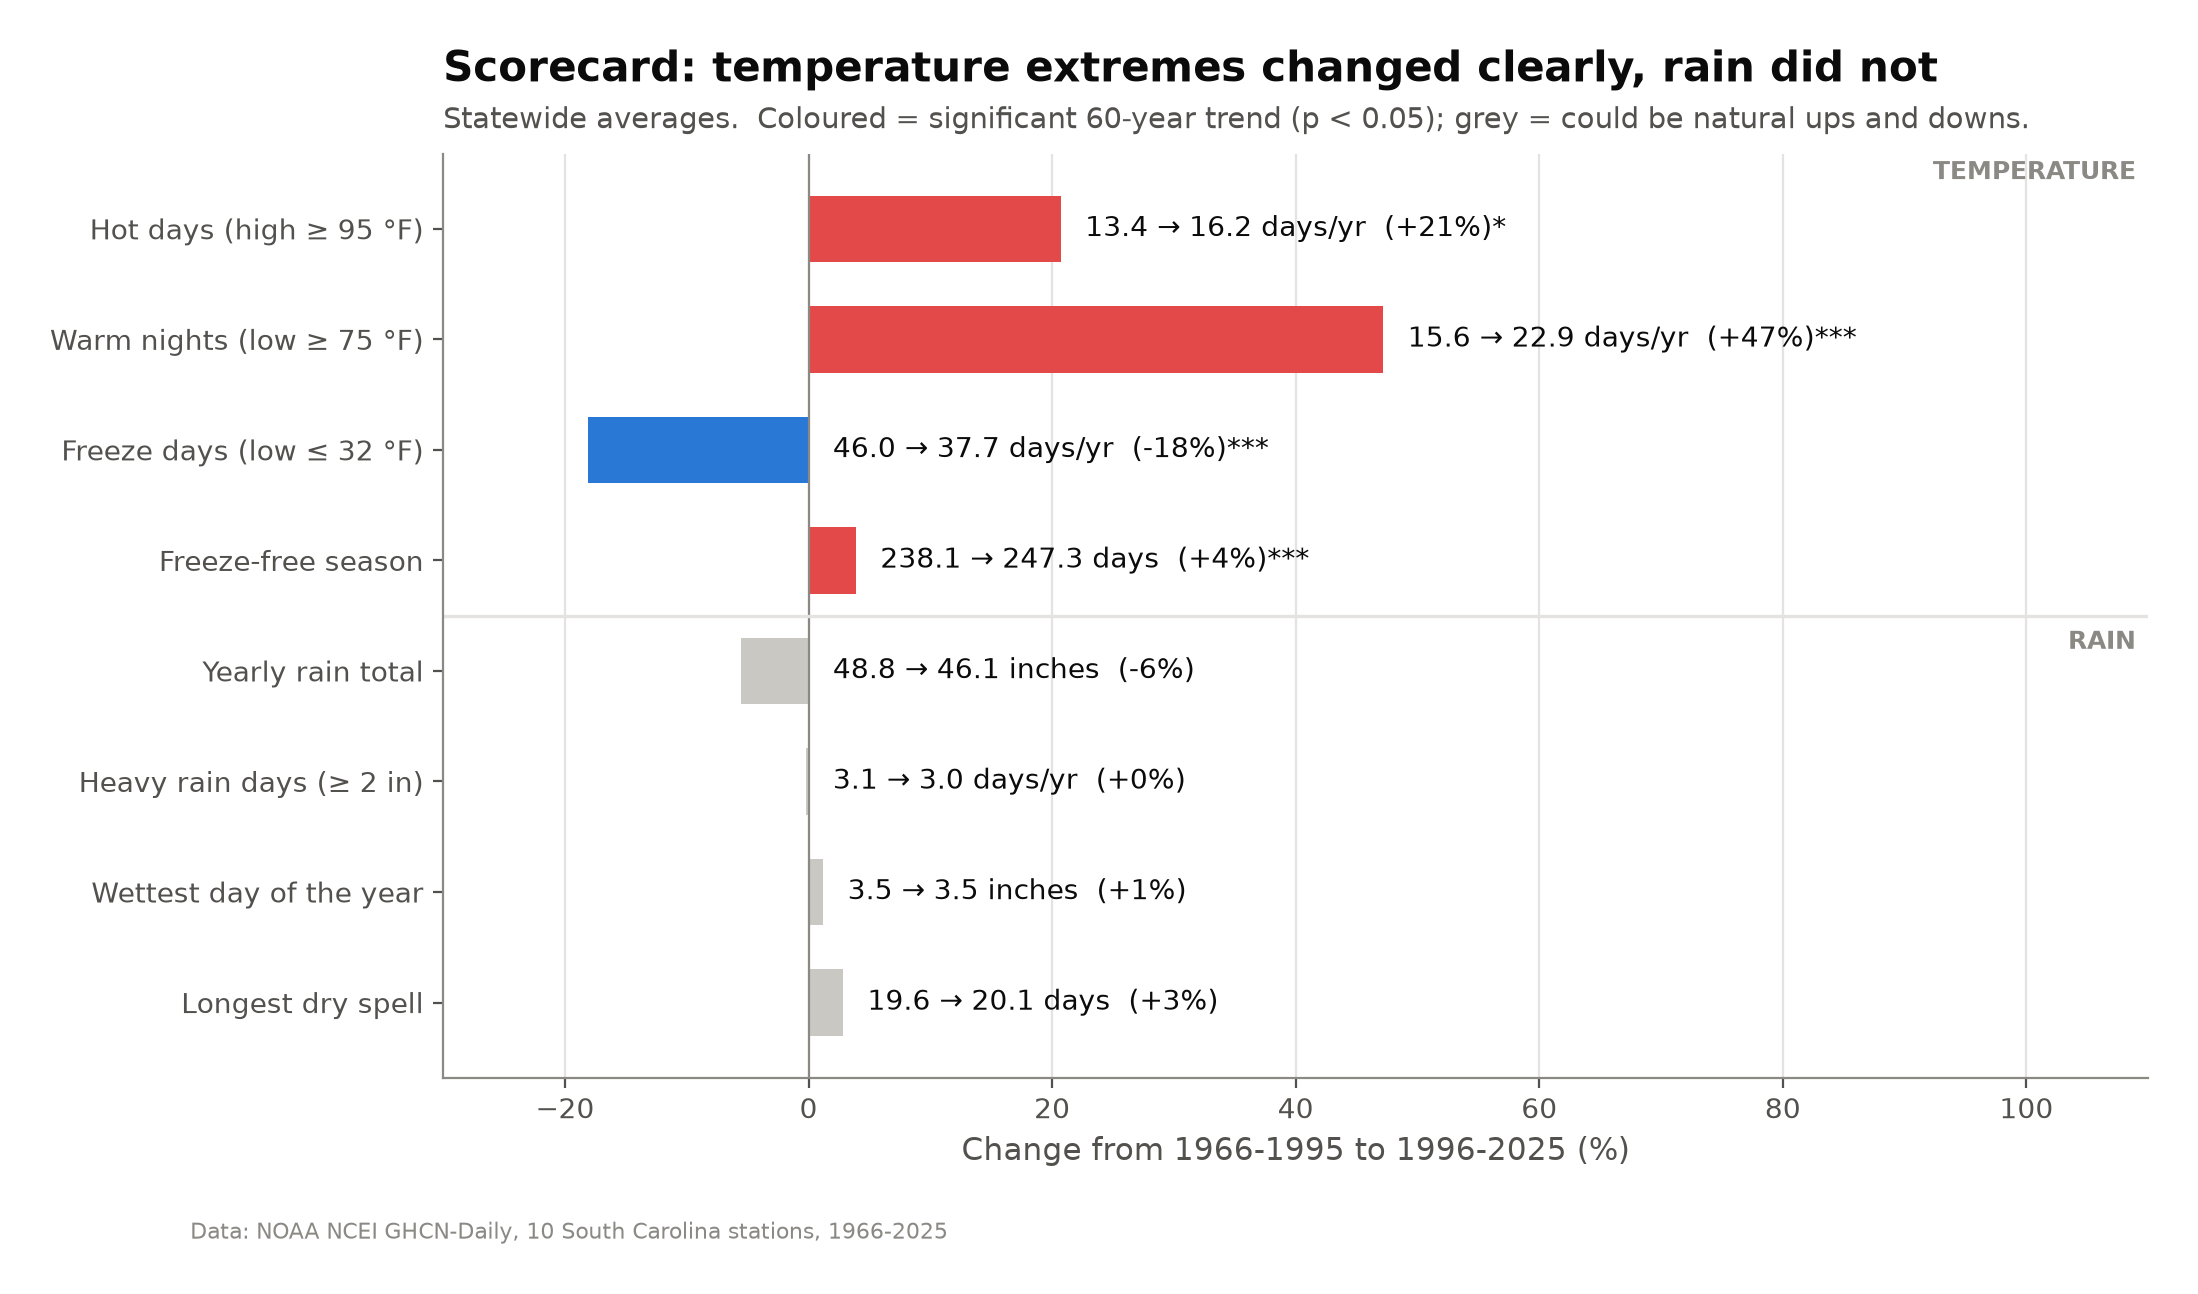

In [12]:
display(Image("figures/fig09_hot_days_and_warm_nights.png", width=900))
display(Image("figures/fig10_freeze_season.png", width=900))
display(Image("figures/fig11_heavy_rain.png", width=900))
display(Image("figures/fig12_extremes_scorecard.png", width=900))

**Answer:** warm nights +47%, freeze days −18%, a ~3-week longer growing season,
hot days +21% – but **no significant change in heavy rain** (p = 0.56).

## Summary

In [13]:
angle_results = (a1, a2, a3)
import run_all
run_all.write_summary(*angle_results)

# Key findings (generated by run_all.py)

Data: NOAA NCEI GHCN-Daily, 10 South Carolina stations, 1966-2025.
Sumter was flagged by the neighbour check and left out of temperature averages.

## Angle 1 - Where is it warming most?
- Statewide warming: **+0.49 °F per decade** (± 0.14, p = 2.6e-09), about +2.9 °F over 60 years.
- Fastest: **Columbia** (+0.58 °F/decade). Slowest trusted station: Anderson (+0.33).
- 9 of 9 trusted stations have a significant warming trend (p < 0.05).
- Region averages (°F/decade): Coast 0.53, Midlands 0.50, Upstate 0.45.

## Angle 2 - When: day or night, which season?
- Nights (daily low) warm at +0.55 °F/decade vs. days (daily high) +0.43 °F/decade on average.
- Nights warm faster than days in 5 of 9 cities - biggest gaps in downtown Charleston and Columbia.
- Winter is warming 1.7x faster than the other seasons.

## Angle 3 - What do people feel: extremes
- Hot days (≥95 °F): 13.4 → 16.2 per year (p = 0.046).
- Warm nights (≥75 °F): 15.6 → 22.9 per year (p